# Phân tích cảm xúc Amazon Fine Food Reviews bằng Học sâu

Môn: Nhập môn Học sâu · Học viên: Nguyễn Tuệ Lâm (20261207M) · GVHD: TS. Trần Việt Trung
Dữ liệu: [Amazon Fine Food Reviews](https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews), 568.454 review.

| Phần | Nội dung |
|---|---|
| 0 | Thiết lập Colab và code dùng chung (`src/`) |
| 1 | Làm sạch dữ liệu |
| 2 | Hiểu dữ liệu (EDA) |
| 3 | Chuẩn bị dữ liệu |
| 4 | BiLSTM + Attention |
| 5 | Fine-tune BERT-base |
| 6 | Đánh giá, so sánh, kết luận |

**Cách chạy:** chọn GPU (T4), đặt `Reviews.csv` vào `MyDrive/sentiment-analysis-project/dataset/`, rồi Run all. Phần 4–5 tự nạp mô hình đã lưu trong `outputs/` (đặt `RETRAIN = True` để huấn luyện lại; khi đó các số trong phần nhận xét có thể lệch nhẹ).

# Phần 0 · Thiết lập môi trường

In [1]:
import os, sys

QUICK_RUN = False
os.environ['QUICK_RUN'] = '1' if QUICK_RUN else '0'

RETRAIN = False
if QUICK_RUN:
    RETRAIN = True

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/sentiment-analysis-project'
    os.makedirs(PROJECT_DIR + '/dataset', exist_ok=True)
    os.chdir(PROJECT_DIR)
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
os.makedirs('src', exist_ok=True)
sys.path.insert(0, os.getcwd())
print('Thư mục làm việc:', os.getcwd())

import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else 'KHÔNG CÓ -> hãy chọn Runtime > Change runtime type > GPU, nếu không BERT sẽ chạy rất chậm')
if not os.path.exists('dataset/Reviews.csv'):
    print('CHƯA CÓ dataset/Reviews.csv trong', os.getcwd(), '-> hãy upload file này trước khi chạy tiếp.')

Mounted at /content/drive
Thư mục làm việc: /content/drive/MyDrive/sentiment-analysis-project
GPU: Tesla T4


### Code dùng chung (`src/`)
Các ô dưới ghi các module dùng chung vào `src/`.

In [2]:
%%writefile src/__init__.py
"""Code dùng chung cho các notebook phân tích cảm xúc (Amazon Fine Food Reviews)."""

Overwriting src/__init__.py


In [3]:
%%writefile src/config.py
"""Cấu hình dùng chung cho mọi notebook: đường dẫn, nhãn, siêu tham số, seed, thiết bị."""
import os
import random
from pathlib import Path

import numpy as np
import torch

ROOT = Path(__file__).resolve().parents[1]
DATA_PATH = ROOT / 'dataset' / 'Reviews.csv'
OUTPUT_DIR = ROOT / 'outputs'
DATA_DIR = OUTPUT_DIR / 'data'
PRED_DIR = OUTPUT_DIR / 'predictions'
BASELINE_DIR = OUTPUT_DIR / 'baseline'
BILSTM_DIR = OUTPUT_DIR / 'bilstm'
BERT_DIR = OUTPUT_DIR / 'bert'
for d in (DATA_DIR, PRED_DIR, BASELINE_DIR, BILSTM_DIR, BERT_DIR):
    d.mkdir(parents=True, exist_ok=True)

LABELS = ['negative', 'neutral', 'positive']
SCORE_TO_LABEL = {1: 0, 2: 0, 3: 1, 4: 2, 5: 2}
PALETTE = {'negative': '#d62728', 'neutral': '#7f7f7f', 'positive': '#2ca02c'}

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ON_GPU = DEVICE.type == 'cuda'

QUICK_RUN = os.environ.get('QUICK_RUN', '0') == '1'

CFG = {
    'sample_size': 30_000 if QUICK_RUN else None,
    'test_small_size': 3_000,
    'lstm_max_vocab': 50_000, 'lstm_min_freq': 3, 'lstm_max_len': 200,
    'lstm_emb_dim': 128, 'lstm_hidden': 128, 'lstm_layers': 1, 'lstm_dropout': 0.3,
    'lstm_batch_size': 256, 'lstm_epochs': 1 if QUICK_RUN else 5, 'lstm_lr': 2e-3, 'lstm_patience': 2,
    'tfidf_max_features': 300_000, 'tfidf_ngram': (1, 2), 'tfidf_min_df': 3, 'tfidf_C_grid': (1.0, 3.0, 10.0, 30.0),
    'trf_name': 'bert-base-uncased',
    'trf_max_len': 256 if ON_GPU else 128,
    'trf_train_size': None if ON_GPU else (800 if QUICK_RUN else 20_000),
    'trf_val_size': None if ON_GPU else (300 if QUICK_RUN else 4_000),
    'trf_batch_size': 32 if ON_GPU else 16,
    'trf_epochs': 1 if QUICK_RUN else 2, 'trf_lr': 3e-5, 'trf_warmup': 0.1, 'trf_weight_decay': 0.01,
    'zs_name': 'cardiffnlp/twitter-roberta-base-sentiment-latest',
}


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def device_info() -> str:
    if ON_GPU:
        return f'PyTorch {torch.__version__} | thiết bị: cuda ({torch.cuda.get_device_name(0)})'
    return f'PyTorch {torch.__version__} | thiết bị: cpu ({torch.get_num_threads()} luồng)'


def setup_notebook() -> None:
    """Thiết lập chung cho notebook: style biểu đồ, tắt cảnh báo, seed."""
    import warnings
    import matplotlib.pyplot as plt
    import pandas as pd
    warnings.filterwarnings('ignore')
    plt.style.use('ggplot')
    pd.set_option('display.max_colwidth', 200)
    try:
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()
    except ImportError:
        pass
    set_seed(SEED)
    print(device_info() + (' | QUICK_RUN' if QUICK_RUN else ''))

Overwriting src/config.py


In [4]:
%%writefile src/text.py
"""Làm sạch và token hoá văn bản."""
import html
import re

import numpy as np
import pandas as pd


def clean_text(text: str) -> str:
    """Làm sạch nhẹ: bỏ HTML, URL, chuẩn hoá khoảng trắng. Giữ dấu câu, chữ hoa và từ phủ định."""
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def build_input_text(summary: pd.Series, body: pd.Series) -> np.ndarray:
    """text = clean(Summary) + '. ' + clean(Text)  (không thêm dấu chấm nếu Summary đã kết thúc bằng . ! ?)."""
    summary_clean = summary.fillna('').astype(str).map(clean_text)
    body_clean = body.astype(str).map(clean_text)
    sep = np.where(summary_clean.str[-1:].isin(['.', '!', '?']), ' ', '. ')
    return np.where(summary_clean.str.len() > 0, summary_clean + sep + body_clean, body_clean)


TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[!?]")


def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(text.lower())


NEGATIONS = {'not', 'no', 'nor', 'never', 'don', "don't", 'didn', "didn't", 'doesn', "doesn't", 'isn', "isn't",
             'wasn', "wasn't", 'weren', "weren't", 'wouldn', "wouldn't", 'couldn', "couldn't", 'won', "won't",
             'aren', "aren't", 'hasn', "hasn't", 'haven', "haven't", 'shouldn', "shouldn't"}

Overwriting src/text.py


In [5]:
%%writefile src/data.py
"""Đọc/ghi dữ liệu trung gian, từ điển, Dataset và DataLoader có bucketing."""
import json
import math
from collections import Counter

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset, Sampler

from .config import DATA_DIR, SEED

CLEAN_PATH = DATA_DIR / 'reviews_clean.pkl'
SPLIT_PATHS = {name: DATA_DIR / f'{name}.pkl' for name in ('train', 'val', 'test')}
CLASS_WEIGHTS_PATH = DATA_DIR / 'class_weights.json'


def load_clean() -> pd.DataFrame:
    if not CLEAN_PATH.exists():
        raise FileNotFoundError(f'Chưa có {CLEAN_PATH}. Hãy chạy notebook 01_data_cleaning trước.')
    return pd.read_pickle(CLEAN_PATH)


def load_splits() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    missing = [p for p in SPLIT_PATHS.values() if not p.exists()]
    if missing:
        raise FileNotFoundError(f'Chưa có {missing[0]}. Hãy chạy notebook 03_data_preparation trước.')
    return tuple(pd.read_pickle(SPLIT_PATHS[n]) for n in ('train', 'val', 'test'))


def load_class_weights() -> np.ndarray:
    return np.array(json.loads(CLASS_WEIGHTS_PATH.read_text(encoding='utf-8'))['weights'], dtype=np.float32)


def stratified_subset(frame: pd.DataFrame, n, seed=SEED) -> pd.DataFrame:
    """Lấy n dòng phân tầng theo nhãn (n = None hoặc n >= số dòng: giữ nguyên)."""
    from sklearn.model_selection import train_test_split
    if n is None or n >= len(frame):
        return frame.reset_index(drop=True)
    return train_test_split(frame, train_size=n, stratify=frame['label'], random_state=seed)[0].reset_index(drop=True)


PAD_IDX, UNK_IDX = 0, 1


class Vocab:
    """Ánh xạ token <-> id. id 0 = <pad>, id 1 = <unk>."""

    def __init__(self, itos: list[str]):
        self.itos = itos
        self.stoi = {w: i for i, w in enumerate(itos)}

    @classmethod
    def build(cls, token_lists, max_size: int, min_freq: int):
        counter = Counter(tok for toks in token_lists for tok in toks)
        itos = ['<pad>', '<unk>'] + [w for w, c in counter.most_common(max_size - 2) if c >= min_freq]
        vocab = cls(itos)
        vocab.counter = counter
        return vocab

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens: list[str], max_len: int) -> list[int]:
        ids = [self.stoi.get(t, UNK_IDX) for t in tokens[:max_len]]
        return ids if ids else [UNK_IDX]

    def save(self, path):
        path.write_text(json.dumps(self.itos, ensure_ascii=False), encoding='utf-8')

    @classmethod
    def load(cls, path):
        return cls(json.loads(path.read_text(encoding='utf-8')))


class SeqDataset(Dataset):
    """Trả về (chỉ số, chuỗi id, nhãn). Chỉ số giúp ghi xác suất về đúng vị trí khi suy luận theo bucket."""

    def __init__(self, ids, labels):
        self.ids, self.labels = ids, labels

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return i, self.ids[i], int(self.labels[i])


class BucketBatchSampler(Sampler):
    """Gom các câu có độ dài gần nhau vào cùng batch để giảm padding.

    shuffle=True : xáo trộn -> chia khối -> sắp theo độ dài trong khối -> cắt batch -> xáo trộn batch.
    shuffle=False: sắp toàn bộ theo độ dài (dùng khi suy luận).
    """

    def __init__(self, lengths, batch_size, shuffle=True, bucket_mult=50, seed=SEED):
        self.lengths, self.bs, self.shuffle = np.asarray(lengths), batch_size, shuffle
        self.chunk = batch_size * bucket_mult if shuffle else len(lengths)
        self.rng = np.random.default_rng(seed)

    def _batches(self):
        idx = self.rng.permutation(len(self.lengths)) if self.shuffle else np.arange(len(self.lengths))
        batches = []
        for s in range(0, len(idx), self.chunk):
            chunk = idx[s:s + self.chunk]
            chunk = chunk[np.argsort(self.lengths[chunk], kind='stable')]
            batches += [chunk[j:j + self.bs] for j in range(0, len(chunk), self.bs)]
        if self.shuffle:
            batches = [batches[k] for k in self.rng.permutation(len(batches))]
        return batches

    def __iter__(self):
        for b in self._batches():
            yield b.tolist()

    def __len__(self):
        return sum(math.ceil(min(self.chunk, len(self.lengths) - s) / self.bs)
                   for s in range(0, len(self.lengths), self.chunk))


def collate_lstm(batch):
    idx, seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    x = torch.full((len(seqs), int(lengths.max())), PAD_IDX, dtype=torch.long)
    for i, s in enumerate(seqs):
        x[i, :len(s)] = torch.tensor(s)
    return torch.tensor(idx), x, lengths, torch.tensor(labels)


def make_collate_transformer(pad_token_id: int):
    def collate(batch):
        idx, seqs, labels = zip(*batch)
        max_len = max(len(s) for s in seqs)
        input_ids = torch.full((len(seqs), max_len), pad_token_id, dtype=torch.long)
        attention_mask = torch.zeros((len(seqs), max_len), dtype=torch.long)
        for i, s in enumerate(seqs):
            input_ids[i, :len(s)] = torch.tensor(s)
            attention_mask[i, :len(s)] = 1
        return torch.tensor(idx), input_ids, attention_mask, torch.tensor(labels)
    return collate


def make_loader(ids, labels, batch_size, shuffle, collate_fn, seed=SEED):
    return DataLoader(SeqDataset(ids, labels),
                      batch_sampler=BucketBatchSampler([len(s) for s in ids], batch_size, shuffle=shuffle, seed=seed),
                      collate_fn=collate_fn)

Overwriting src/data.py


In [6]:
%%writefile src/training.py
"""Vòng huấn luyện và suy luận cho BiLSTM."""
import copy
import time

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

from .config import DEVICE


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total, n = 0.0, 0
    for _, x, _, y in tqdm(loader, desc='train', leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item() * len(y)
        n += len(y)
    return total / n


@torch.inference_mode()
def predict_lstm(model, loader, criterion=None):
    """Trả về (xác suất (N, 3) theo đúng thứ tự dữ liệu gốc, loss trung bình nếu có criterion)."""
    model.eval()
    n = len(loader.dataset)
    probs, total = np.zeros((n, 3), dtype=np.float32), 0.0
    for idx, x, _, y in loader:
        logits = model(x.to(DEVICE))
        if criterion is not None:
            total += criterion(logits, y.to(DEVICE)).item() * len(y)
        probs[idx.numpy()] = torch.softmax(logits, dim=-1).cpu().numpy()
    return probs, total / n


def fit_bilstm(model, train_loader, val_loader, y_val, criterion, epochs, lr, patience,
               weight_decay=1e-4, ckpt_path=None, verbose=True):
    """Huấn luyện với AdamW + ReduceLROnPlateau (theo Macro-F1 validation) + early stopping.

    Giữ lại trọng số của epoch có Macro-F1 validation cao nhất và nạp lại vào `model`.
    Trả về (lịch sử từng epoch, Macro-F1 validation tốt nhất, thời gian huấn luyện tính bằng giây).
    """
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=0)
    history, best_f1, best_state, bad_epochs = [], -1.0, None, 0
    t_start = time.time()
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_probs, val_loss = predict_lstm(model, val_loader, criterion)
        val_pred = val_probs.argmax(1)
        val_acc, val_f1 = accuracy_score(y_val, val_pred), f1_score(y_val, val_pred, average='macro')
        history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                        'val_acc': val_acc, 'val_macro_f1': val_f1, 'lr': optimizer.param_groups[0]['lr']})
        if verbose:
            print(f'Epoch {epoch}: train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f} '
                  f'| val_macro_F1={val_f1:.4f} | lr={optimizer.param_groups[0]["lr"]:.1e} | {time.time() - t0:.0f}s')
        scheduler.step(val_f1)
        if val_f1 > best_f1:
            best_f1, bad_epochs = val_f1, 0
            best_state = copy.deepcopy(model.state_dict())
            if ckpt_path is not None:
                torch.save(best_state, ckpt_path)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                if verbose:
                    print(f'Early stopping: validation Macro-F1 không cải thiện sau {bad_epochs} epoch.')
                break
    train_time = time.time() - t_start
    model.load_state_dict(best_state)
    return history, best_f1, train_time


Overwriting src/training.py


In [7]:
%%writefile src/models.py
"""Kiến trúc mạng nơ-ron."""
import torch
import torch.nn as nn

from .data import PAD_IDX


class BiLSTMAttention(nn.Module):
    """Embedding -> Dropout -> (Bi)LSTM -> Attention pooling -> Dropout -> Linear.

    Mặc định (bidirectional=True, use_attention=True) là mô hình chính của bài.
    Hai tuỳ chọn còn lại (một chiều / trung bình thay attention) không được dùng trong báo cáo cuối.
    """

    def __init__(self, vocab_size, emb_dim, hidden, n_layers, n_classes, dropout, pad_idx=PAD_IDX,
                 bidirectional=True, use_attention=True):
        super().__init__()
        self.pad_idx = pad_idx
        self.use_attention = use_attention
        out_dim = hidden * (2 if bidirectional else 1)
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=n_layers, batch_first=True, bidirectional=bidirectional,
                            dropout=dropout if n_layers > 1 else 0.0)
        if use_attention:
            self.attn = nn.Linear(out_dim, 1)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(out_dim, n_classes))

    def forward(self, x, return_attn=False):
        pad = x == self.pad_idx
        emb = self.emb_dropout(self.embedding(x))
        out, _ = self.lstm(emb)
        if self.use_attention:
            scores = self.attn(out).squeeze(-1).masked_fill(pad, -1e9)
            alpha = torch.softmax(scores, dim=1)
        else:
            keep = (~pad).float()
            alpha = keep / keep.sum(dim=1, keepdim=True).clamp(min=1.0)
        context = torch.bmm(alpha.unsqueeze(1), out).squeeze(1)
        logits = self.classifier(context)
        return (logits, alpha) if return_attn else logits


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


Overwriting src/models.py


In [8]:
%%writefile src/evaluation.py
"""Độ đo, ma trận nhầm lẫn, bootstrap, hiệu chỉnh ngưỡng và lưu/đọc dự đoán của từng mô hình."""
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from .config import LABELS, PRED_DIR
from .data import collate_lstm, make_loader
from .text import tokenize
from .training import predict_lstm
from .transformer import predict_transformer

METRIC_COLS = ['Accuracy', 'Macro-F1', 'Weighted-F1', 'F1 negative', 'F1 neutral', 'F1 positive']


def compute_metrics(y_true, y_pred) -> dict:
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2], zero_division=0)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro-F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Weighted-F1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1 negative': per_class[0], 'F1 neutral': per_class[1], 'F1 positive': per_class[2],
    }


def report(name, y_true, y_pred) -> dict:
    m = compute_metrics(y_true, y_pred)
    print(f'=== {name} ===  Accuracy = {m["Accuracy"]:.4f} | Macro-F1 = {m["Macro-F1"]:.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4, zero_division=0))
    return m


def plot_confusion(y_true, y_pred, title, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f'{cm_norm[i, j]:.1%}\n({cm[i, j]:,})' for j in range(3)] for i in range(3)])
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_norm, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set(xlabel='Dự đoán', ylabel='Thực tế', title=title)
    return ax


def plot_history(hist, title, step_losses=None):
    """Đường cong học. Có `step_losses` (BERT): loss theo bước + độ đo validation; không có (BiLSTM): loss train/val + độ đo."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    if step_losses is not None and len(step_losses):
        window = max(1, len(step_losses) // 50)
        axes[0].plot(step_losses, alpha=.25, color='#4c72b0', label='loss từng bước')
        axes[0].plot(pd.Series(step_losses).rolling(window, min_periods=1).mean(), color='#4c72b0',
                     label=f'trung bình trượt ({window} bước)')
        per_epoch = len(step_losses) // len(hist)
        for e in range(1, len(hist)):
            axes[0].axvline(e * per_epoch, ls='--', color='gray', lw=1)
        axes[0].set(title=f'{title} – train loss theo bước', xlabel='Bước (batch)', ylabel='Loss')
    else:
        axes[0].plot(hist['epoch'], hist['train_loss'], 'o-', label='train')
        axes[0].plot(hist['epoch'], hist['val_loss'], 's-', label='validation')
        axes[0].set(title=f'{title} – loss (cross-entropy có trọng số)', xlabel='Epoch', ylabel='Loss')
    axes[0].legend()
    axes[1].plot(hist['epoch'], hist['val_acc'], 'o-', label='val accuracy')
    axes[1].plot(hist['epoch'], hist['val_macro_f1'], 's-', label='val Macro-F1')
    axes[1].set(title=f'{title} – độ đo trên validation', xlabel='Epoch')
    axes[1].legend()
    for ax in axes:
        ax.xaxis.get_major_locator().set_params(integer=True)
    plt.tight_layout()
    plt.show()


def confusion_table(y_true, y_pred) -> pd.DataFrame:
    """Ma trận nhầm lẫn dạng bảng, chuẩn hoá theo hàng (mỗi hàng = 100% review của một nhãn thật)."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    table = pd.DataFrame(cm / cm.sum(axis=1, keepdims=True).clip(min=1),
                         index=[f'thật: {l}' for l in LABELS], columns=[f'đoán: {l}' for l in LABELS])
    return table.style.format('{:.1%}')


def macro_f1_from_confusion(cm) -> float:
    """Macro-F1 từ ma trận nhầm lẫn 3x3; F1_c = 2TP / (2TP + FP + FN)."""
    tp = np.diag(cm).astype(float)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return float(np.mean(np.where(denom > 0, 2 * tp / np.where(denom > 0, denom, 1), 0.0)))


def bootstrap_macro_f1(y_true, preds: dict, n_boot=1000, seed=42) -> dict:
    """Lấy mẫu có hoàn lại tập test n_boot lần, dùng CHUNG một mẫu cho mọi mô hình (để so sánh cặp được).

    preds: {tên mô hình: nhãn dự đoán}. Trả về {tên: mảng n_boot giá trị Macro-F1}.
    """
    y = np.asarray(y_true)
    P = {k: np.asarray(v) for k, v in preds.items()}
    rng = np.random.default_rng(seed)
    scores = {k: np.empty(n_boot) for k in P}
    for b in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        yb = y[idx]
        for k, p in P.items():
            scores[k][b] = macro_f1_from_confusion(np.bincount(yb * 3 + p[idx], minlength=9).reshape(3, 3))
    return scores


def summarize_bootstrap(scores: dict, point: dict, level=0.95) -> pd.DataFrame:
    lo, hi = (1 - level) / 2 * 100, (1 + level) / 2 * 100
    return pd.DataFrame({k: {'Macro-F1': point[k], f'CI {level:.0%} thấp': np.percentile(v, lo),
                             f'CI {level:.0%} cao': np.percentile(v, hi)} for k, v in scores.items()}).T


def paired_difference(scores: dict, a: str, b: str, level=0.95) -> dict:
    """Chênh lệch Macro-F1 giữa hai mô hình (a - b) trên cùng các mẫu bootstrap."""
    d = scores[a] - scores[b]
    lo, hi = (1 - level) / 2 * 100, (1 + level) / 2 * 100
    return {'mean': float(d.mean()), 'low': float(np.percentile(d, lo)), 'high': float(np.percentile(d, hi)),
            'P(a > b)': float((d > 0).mean())}


def predict_with_neutral_bias(probs, bias: float) -> np.ndarray:
    """Cộng `bias` vào log-xác suất của lớp neutral rồi lấy argmax (bias < 0: đoán neutral ít đi)."""
    logp = np.log(np.clip(np.asarray(probs, dtype=np.float64), 1e-9, 1.0))
    logp[:, 1] += bias
    return logp.argmax(1)


def tune_neutral_bias(val_probs, y_val, grid=None):
    """Chọn `bias` cho lớp neutral làm Macro-F1 trên VALIDATION cao nhất (không dùng test)."""
    grid = np.round(np.arange(-2.0, 2.0001, 0.1), 2) if grid is None else np.asarray(grid)
    y = np.asarray(y_val)
    scores = np.array([macro_f1_from_confusion(
        np.bincount(y * 3 + predict_with_neutral_bias(val_probs, b), minlength=9).reshape(3, 3)) for b in grid])
    return float(grid[scores.argmax()]), grid, scores


def predict_lstm_probs(model, vocab, texts, max_len, batch_size=256) -> np.ndarray:
    """Xác suất của BiLSTM cho một danh sách văn bản đã làm sạch (theo lô, nhanh hơn từng câu một)."""
    ids = [vocab.encode(tokenize(t), max_len) for t in texts]
    loader = make_loader(ids, np.zeros(len(ids), dtype=int), batch_size, shuffle=False, collate_fn=collate_lstm)
    return predict_lstm(model, loader)[0]


def _slug(name: str) -> str:
    return re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')


def save_predictions(name: str, probs: np.ndarray, info: dict, test_index=None) -> None:
    """Lưu xác suất trên tập test và thông tin phụ (thời gian train, số tham số...) để notebook 07 so sánh.

    test_index: vị trí các dòng của tập test được dự đoán (None = toàn bộ tập test).
    """
    slug = _slug(name)
    arrays = {'probs': probs}
    if test_index is not None:
        arrays['test_index'] = np.asarray(test_index)
    np.savez_compressed(PRED_DIR / f'{slug}.npz', **arrays)
    (PRED_DIR / f'{slug}.json').write_text(json.dumps({'name': name, **info}, ensure_ascii=False, indent=2),
                                           encoding='utf-8')


def load_predictions() -> dict:
    """Trả về {tên mô hình: {'probs', 'test_index', ...info}} cho mọi mô hình đã lưu."""
    out = {}
    for meta_path in sorted(PRED_DIR.glob('*.json')):
        info = json.loads(meta_path.read_text(encoding='utf-8'))
        arrays = np.load(meta_path.with_suffix('.npz'))
        info['probs'] = arrays['probs']
        info['test_index'] = arrays['test_index'] if 'test_index' in arrays else None
        out[info.pop('name')] = info
    return out

Overwriting src/evaluation.py


In [9]:
%%writefile src/explain.py
"""Diễn giải BiLSTM + Attention: tô màu từ theo trọng số attention."""
import html

import numpy as np
import torch
from IPython.display import HTML, display

from .config import DEVICE, LABELS
from .text import clean_text, tokenize


@torch.inference_mode()
def lstm_explain(model, vocab, text, max_len):
    """Trả về (tokens, trọng số attention, xác suất 3 lớp) cho một câu."""
    model.eval()
    toks = tokenize(clean_text(text))[:max_len] or ['<unk>']
    ids = vocab.encode(toks, max_len)
    logits, alpha = model(torch.tensor([ids], device=DEVICE), return_attn=True)
    return toks, alpha[0].cpu().numpy(), torch.softmax(logits[0], -1).cpu().numpy()


def lstm_predict_texts(model, vocab, texts, max_len) -> np.ndarray:
    return np.stack([lstm_explain(model, vocab, t, max_len)[2] for t in texts])


def show_attention(model, vocab, text, max_len, true_label=None):
    toks, alpha, probs = lstm_explain(model, vocab, text, max_len)
    a = alpha / alpha.max()
    spans = ' '.join(f'<span style="background-color: rgba(220,50,50,{w:.2f}); padding:1px 2px; border-radius:3px">'
                     f'{html.escape(t)}</span>' for t, w in zip(toks, a))
    head = f'<b>Dự đoán:</b> {LABELS[probs.argmax()]} ({probs.max():.0%})'
    if true_label is not None:
        head += f' &nbsp;|&nbsp; <b>Thực tế:</b> {LABELS[true_label]}'
    display(HTML(f'<div style="margin:6px 0 14px 0; line-height:1.9">{head}<br>{spans}</div>'))

Overwriting src/explain.py


In [10]:
%%writefile src/transformer.py
"""Suy luận và fine-tune mô hình Transformer (BERT, RoBERTa zero-shot) bằng HuggingFace."""
import json
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

from .config import DEVICE, LABELS, ON_GPU


@torch.inference_mode()
def predict_transformer(model, tokenizer, texts, max_len, batch_size=64, desc='Suy luận'):
    """Dự đoán xác suất bằng mô hình HuggingFace; sắp theo độ dài để padding động ít tốn kém nhất."""
    model.eval()
    texts = list(texts)
    order = np.argsort([len(t) for t in texts])
    probs = np.zeros((len(texts), model.config.num_labels), dtype=np.float32)
    for i in tqdm(range(0, len(texts), batch_size), desc=desc, leave=False):
        idx = order[i:i + batch_size]
        enc = tokenizer([texts[j] for j in idx], truncation=True, max_length=max_len,
                        padding=True, return_tensors='pt').to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=ON_GPU):
            logits = model(**enc).logits
        probs[idx] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    return probs


def zero_shot_probs(model, tokenizer, texts, max_len, desc='Zero-shot') -> np.ndarray:
    """Xác suất của một mô hình sentiment 3 nhãn có sẵn, đã đổi cột về đúng thứ tự LABELS của bài."""
    to_ours = np.array([LABELS.index(model.config.id2label[i].lower()) for i in range(model.config.num_labels)])
    p = predict_transformer(model, tokenizer, texts, max_len, desc=desc)
    out = np.zeros_like(p)
    out[:, to_ours] = p
    return out


def load_classifier(path_or_name, num_labels=None):
    """Nạp mô hình phân loại; khi nạp từ tên gốc (chưa fine-tune) thì khai báo 3 nhãn của bài."""
    kwargs = {} if num_labels is None else dict(num_labels=num_labels, id2label=dict(enumerate(LABELS)),
                                                label2id={l: i for i, l in enumerate(LABELS)})
    return AutoModelForSequenceClassification.from_pretrained(path_or_name, **kwargs).to(DEVICE)


def build_optimizer(model, lr, weight_decay, warmup, total_steps):
    """AdamW (weight decay chỉ cho ma trận trọng số, không cho bias và LayerNorm) + warmup tuyến tính rồi giảm tuyến tính."""
    no_decay = ['bias', 'LayerNorm.weight']
    groups = [
        {'params': [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], 'weight_decay': weight_decay},
        {'params': [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], 'weight_decay': 0.0},
    ]
    optimizer = torch.optim.AdamW(groups, lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(warmup * total_steps), total_steps)
    return optimizer, scheduler


def fit_transformer(model, tokenizer, train_loader, val_texts, y_val, criterion, epochs, lr, warmup,
                    weight_decay, max_len, save_dir):
    """Fine-tune toàn bộ mạng. Sau mỗi epoch chấm Macro-F1 trên validation và lưu ngay nếu là epoch tốt nhất.

    Không có early stopping: luôn chạy đủ `epochs`. Trả về (mô hình đã nạp lại epoch tốt nhất, lịch sử từng epoch,
    loss từng bước, Macro-F1 validation tốt nhất, thời gian huấn luyện tính bằng giây).
    """
    total_steps = len(train_loader) * epochs
    optimizer, scheduler = build_optimizer(model, lr, weight_decay, warmup, total_steps)
    scaler = torch.amp.GradScaler('cuda', enabled=ON_GPU)
    history, step_losses, best_f1 = [], [], -1.0
    t_start = time.time()
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        for _, input_ids, attention_mask, y in tqdm(train_loader, desc=f'epoch {epoch}', leave=False):
            input_ids, attention_mask, y = input_ids.to(DEVICE), attention_mask.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=ON_GPU):
                logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step_losses.append(loss.item())

        val_pred = predict_transformer(model, tokenizer, val_texts, max_len, desc='validation').argmax(1)
        val_acc, val_f1 = accuracy_score(y_val, val_pred), f1_score(y_val, val_pred, average='macro')
        epoch_loss = float(np.mean(step_losses[-len(train_loader):]))
        history.append({'epoch': epoch, 'train_loss': epoch_loss, 'val_acc': val_acc, 'val_macro_f1': val_f1})
        print(f'Epoch {epoch}: train_loss={epoch_loss:.4f} | val_acc={val_acc:.4f} | '
              f'val_macro_F1={val_f1:.4f} | {(time.time() - t0) / 60:.1f} phút')
        if val_f1 > best_f1:
            best_f1 = val_f1
            model.save_pretrained(save_dir)
            tokenizer.save_pretrained(save_dir)
        pd.DataFrame(history).to_csv(save_dir / 'history.csv', index=False)
        if ON_GPU:
            torch.cuda.empty_cache()
    train_time = time.time() - t_start
    model = load_classifier(save_dir)
    np.save(save_dir / 'step_losses.npy', np.array(step_losses))
    (save_dir / 'train_info.json').write_text(json.dumps({'train_time_s': train_time, 'best_val_macro_f1': best_f1, 'max_len': max_len}, indent=2))
    return model, pd.DataFrame(history), step_losses, best_f1, train_time

Overwriting src/transformer.py


# Phần 1 · Làm sạch dữ liệu (Data Cleaning)

## 1.1 Bài toán
- **Đầu vào:** văn bản review tiếng Anh (`Summary` + `Text`). **Đầu ra:** một trong 3 nhãn negative / neutral / positive.
- **Nhãn yếu** từ số sao: 1–2 → negative, 3 → neutral, 4–5 → positive.
- **Thách thức:** nhãn mất cân bằng, lớp neutral mơ hồ, dữ liệu trùng lặp và nhiễu, phủ định và mỉa mai.
- **Độ đo chính: Macro-F1** (trung bình F1 của 3 lớp), vì luôn đoán *positive* đã đạt ≈78% accuracy.

| Mô hình | Loại |
|---|---|
| BiLSTM + Attention | mạng hồi quy, huấn luyện từ đầu |
| BERT-base | Transformer tiền huấn luyện, fine-tune |
| Luôn đoán positive | mốc tham chiếu, không học |

## 1.2 Cấu hình
Siêu tham số nằm trong `src/config.py` (biến `CFG`).

In [11]:
import time
import pandas as pd
from IPython.display import display

from src.config import CFG, DATA_PATH, LABELS, SCORE_TO_LABEL, setup_notebook
from src.data import CLEAN_PATH

setup_notebook()
pd.Series(CFG, name='giá trị').to_frame()

PyTorch 2.14.1+cu130 | thiết bị: cuda (Tesla T4)


,giá trị
sample_size,None
test_small_size,3000
lstm_max_vocab,50000
lstm_min_freq,3
lstm_max_len,200
lstm_emb_dim,128
lstm_hidden,128
lstm_layers,1
lstm_dropout,0.3
lstm_batch_size,256


## 1.3 Đọc dữ liệu
Review thực phẩm trên Amazon (10/1999–10/2012). `Score` (1–5) tạo nhãn. `HelpfulnessNumerator/Denominator` chỉ dùng để kiểm tra dữ liệu (tử số không thể lớn hơn mẫu số) và vẽ biểu đồ, **không** đưa vào mô hình.

In [12]:
t0 = time.time()
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head(1)

(568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labr...


In [13]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


## 1.4 Kiểm tra chất lượng dữ liệu
Kiểm tra giá trị thiếu, review trùng lặp và Helpfulness không hợp lệ.

In [14]:
DUP_KEY = ['UserId', 'ProfileName', 'Time', 'Text']

print('Giá trị thiếu theo cột:')
print(raw.isna().sum())
print()
print('Dòng trùng hoàn toàn      :', raw.duplicated().sum())
print('Review trùng (user, time, text):', raw.duplicated(subset=DUP_KEY).sum())
print('Text trùng                :', raw['Text'].duplicated().sum())
print('Helpfulness không hợp lệ  :', (raw['HelpfulnessNumerator'] > raw['HelpfulnessDenominator']).sum())

Giá trị thiếu theo cột:
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

Dòng trùng hoàn toàn      : 0
Review trùng (user, time, text): 174521
Text trùng                : 174875
Helpfulness không hợp lệ  : 2


Khoảng **31%** dòng là review trùng: cùng người, cùng thời điểm, cùng nội dung nhưng khác `ProductId` (Amazon dùng chung review cho các biến thể sản phẩm). Nếu giữ lại, cùng một review có thể nằm ở cả train và test (**rò rỉ dữ liệu**).

In [15]:
dup_groups = raw[raw.duplicated(subset=DUP_KEY, keep=False)]
example_key = dup_groups.iloc[0][DUP_KEY]
raw[(raw[DUP_KEY] == example_key).all(axis=1)][['Id', 'ProductId', 'UserId', 'Score', 'Time', 'Summary']]

,Id,ProductId,UserId,Score,Time,Summary
3,4,B000UA0QIQ,A395BORC6FGVXV,2,1307923200,Cough Medicine
136303,136304,B002Y7526Y,A395BORC6FGVXV,2,1307923200,Cough Medicine
544172,544173,B000U9WZ54,A395BORC6FGVXV,2,1307923200,Cough Medicine


## 1.5 Làm sạch dữ liệu
1. Loại review trùng theo khoá (`UserId`, `ProfileName`, `Time`, `Text`), giữ bản đầu tiên.
2. Loại dòng có `HelpfulnessNumerator > HelpfulnessDenominator`.
3. Loại các `Text` còn trùng nội dung (spam, copy giữa nhiều tài khoản).
4. Điền `Summary` thiếu bằng chuỗi rỗng, tạo nhãn cảm xúc từ `Score`.

In [16]:
steps = [('Dữ liệu gốc', len(raw))]
df = raw.drop_duplicates(subset=DUP_KEY, keep='first')
steps.append(('Bỏ review trùng (user, time, text)', len(df)))
df = df[df['HelpfulnessNumerator'] <= df['HelpfulnessDenominator']]
steps.append(('Bỏ Helpfulness không hợp lệ', len(df)))
df = df.drop_duplicates(subset=['Text'], keep='first')
steps.append(('Bỏ Text trùng', len(df)))

df = df.copy()
df['Summary'] = df['Summary'].fillna('').astype(str)
df['label'] = df['Score'].map(SCORE_TO_LABEL)
df['sentiment'] = df['label'].map(dict(enumerate(LABELS)))
df['date'] = pd.to_datetime(df['Time'], unit='s')
df = df.reset_index(drop=True)

clean_steps = pd.DataFrame(steps, columns=['Bước', 'Số dòng còn lại'])
display(clean_steps)

,Bước,Số dòng còn lại
0,Dữ liệu gốc,568454
1,"Bỏ review trùng (user, time, text)",393933
2,Bỏ Helpfulness không hợp lệ,393931
3,Bỏ Text trùng,393577


## 1.6 Lưu dữ liệu đã làm sạch
Lưu dạng pickle để các phần sau đọc lại nhanh.

In [17]:
df.to_pickle(CLEAN_PATH)
print(f'Đã lưu {len(df):,} review vào {CLEAN_PATH}')
df[['ProductId', 'UserId', 'Score', 'sentiment', 'date', 'Summary', 'Text']].head()

Đã lưu 393,577 review vào /content/drive/MyDrive/sentiment-analysis-project/outputs/data/reviews_clean.pkl


,ProductId,UserId,Score,sentiment,date,Summary,Text
0,B001E4KFG0,A3SGXH7AUHU8GW,5,positive,2011-04-27,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labr...
1,B00813GRG4,A1D87F6ZCVE5NK,1,negative,2012-09-07,Not as Advertised,"Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as ""Jumbo""."
2,B000LQOCH0,ABXLMWJIXXAIN,4,positive,2008-08-18,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then liberally coated with ..."
3,B000UA0QIQ,A395BORC6FGVXV,2,negative,2011-06-13,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in addition to the Root Beer Extract I ordered (which was good) and made some cherry soda. The fl...
4,B006K2ZZ7K,A1UQRSCLF8GW1T,5,positive,2012-10-21,Great taffy,"Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If your a taffy lover, this is a deal."


# Phần 2 · Hiểu dữ liệu (EDA)

**Đầu vào:** `outputs/data/reviews_clean.pkl`. EDA trả lời: phân bố nhãn, độ dài văn bản, thay đổi theo thời gian, helpfulness, người dùng và sản phẩm, nhiễu, từ vựng từng lớp.

In [18]:
from collections import Counter

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.config import LABELS, PALETTE, SEED, setup_notebook
from src.data import load_clean
from src.text import NEGATIONS, clean_text, tokenize

setup_notebook()
nltk.download('stopwords', quiet=True)
df = load_clean()
print(f'{len(df):,} review sau làm sạch')

PyTorch 2.14.1+cu130 | thiết bị: cuda (Tesla T4)
393,577 review sau làm sạch


## 2.1 Phân bố số sao và nhãn cảm xúc

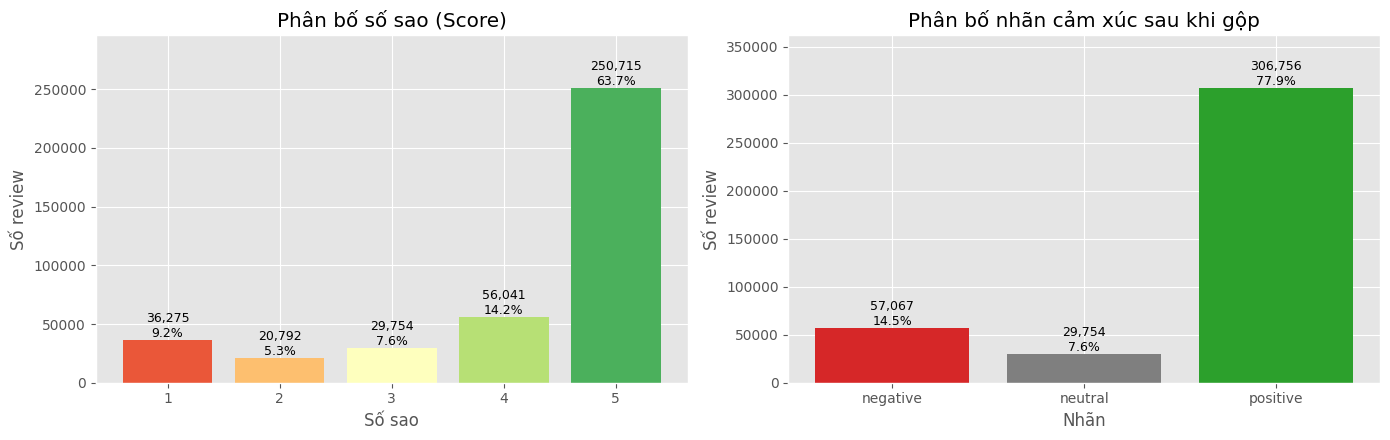

Tỉ lệ mất cân bằng positive : neutral = 10.3 : 1


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

score_counts = df['Score'].value_counts().sort_index()
axes[0].bar(score_counts.index.astype(str), score_counts.values, color=sns.color_palette('RdYlGn', 5))
for i, v in enumerate(score_counts.values):
    axes[0].text(i, v, f'{v:,}\n{v / len(df):.1%}', ha='center', va='bottom', fontsize=9)
axes[0].set(title='Phân bố số sao (Score)', xlabel='Số sao', ylabel='Số review', ylim=(0, score_counts.max() * 1.18))

label_counts = df['sentiment'].value_counts().reindex(LABELS)
axes[1].bar(LABELS, label_counts.values, color=[PALETTE[l] for l in LABELS])
for i, v in enumerate(label_counts.values):
    axes[1].text(i, v, f'{v:,}\n{v / len(df):.1%}', ha='center', va='bottom', fontsize=9)
axes[1].set(title='Phân bố nhãn cảm xúc sau khi gộp', xlabel='Nhãn', ylabel='Số review', ylim=(0, label_counts.max() * 1.18))
plt.tight_layout()
plt.show()

print(f'Tỉ lệ mất cân bằng positive : neutral = {label_counts["positive"] / label_counts["neutral"]:.1f} : 1')

**Nhận xét:** hơn 3/4 review là positive, neutral chỉ ≈7–8% (≈10 : 1). "Luôn đoán positive" đạt Accuracy ≈78% nhưng Macro-F1 chỉ ≈0,29. → chia phân tầng, trọng số lớp, độ đo chính là Macro-F1.

## 2.2 Độ dài văn bản

,count,mean,std,min,50%,75%,90%,95%,99%,max
n_words_text,393577.0,79.8,77.2,3.0,57.0,97.0,159.0,215.0,377.0,3432.0
n_words_summary,393577.0,4.1,2.6,0.0,3.0,5.0,8.0,9.0,12.0,42.0


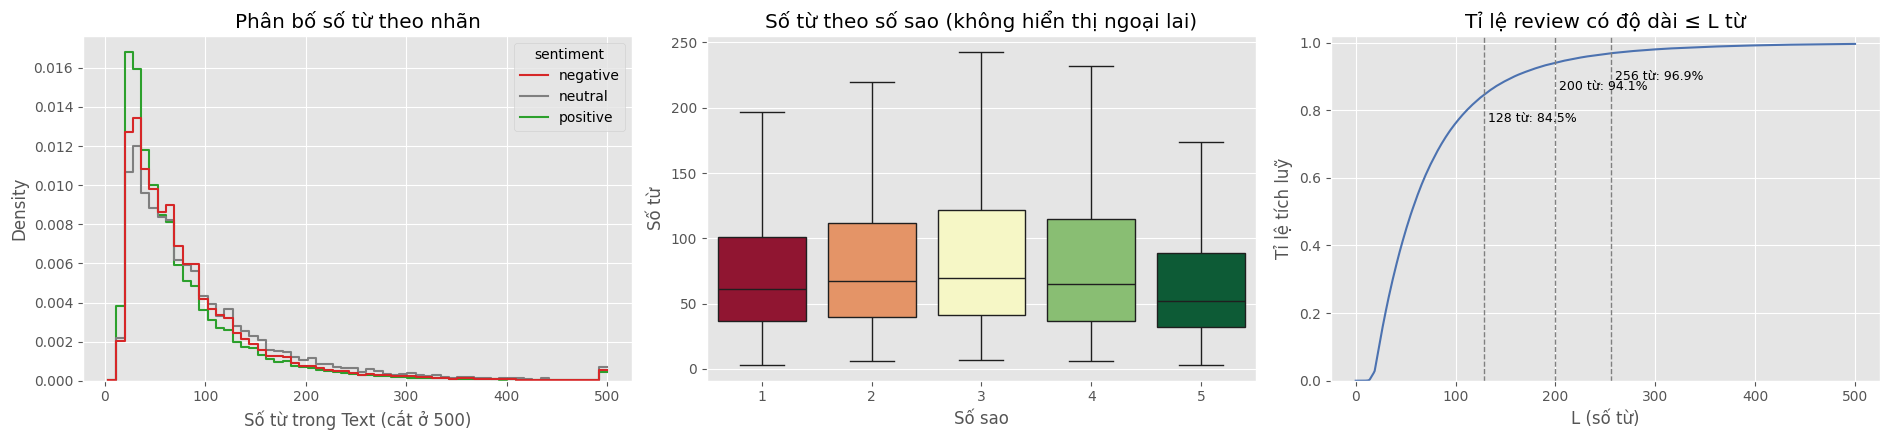

In [20]:
df['n_words_text'] = df['Text'].str.split().str.len()
df['n_words_summary'] = df['Summary'].str.split().str.len()
display(df[['n_words_text', 'n_words_summary']]
        .describe(percentiles=[.5, .75, .9, .95, .99]).T.round(1))

df['n_words_clip'] = df['n_words_text'].clip(upper=500)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
sns.histplot(data=df, x='n_words_clip', hue='sentiment', hue_order=LABELS, palette=PALETTE, bins=60,
             stat='density', common_norm=False, element='step', fill=False, ax=axes[0])
axes[0].set(title='Phân bố số từ theo nhãn', xlabel='Số từ trong Text (cắt ở 500)')

sns.boxplot(data=df, x='Score', y='n_words_text', hue='Score', palette='RdYlGn', legend=False, showfliers=False, ax=axes[1])
axes[1].set(title='Số từ theo số sao (không hiển thị ngoại lai)', xlabel='Số sao', ylabel='Số từ')

lens = np.sort(df['n_words_text'].values)
grid = np.arange(0, 501)
axes[2].plot(grid, np.searchsorted(lens, grid, side='right') / len(lens), color='#4c72b0')
for L in [128, 200, 256]:
    cov = (lens <= L).mean()
    axes[2].axvline(L, ls='--', color='gray', lw=1)
    axes[2].text(L + 4, cov - 0.08, f'{L} từ: {cov:.1%}', fontsize=9)
axes[2].set(title='Tỉ lệ review có độ dài ≤ L từ', xlabel='L (số từ)', ylabel='Tỉ lệ tích luỹ', ylim=(0, 1.02))
plt.tight_layout()
plt.show()

**Nhận xét:** độ dài lệch phải (trung vị 57 từ, dài nhất >3.000). `max_len` = 200 từ (BiLSTM) phủ ≈93% review; 256 token (BERT) cắt ≈6% (đo ở Phần 5). Summary ngắn nhưng giàu cảm xúc nên ghép vào đầu Text. → padding động và bucketing.

## 2.3 Diễn biến theo thời gian

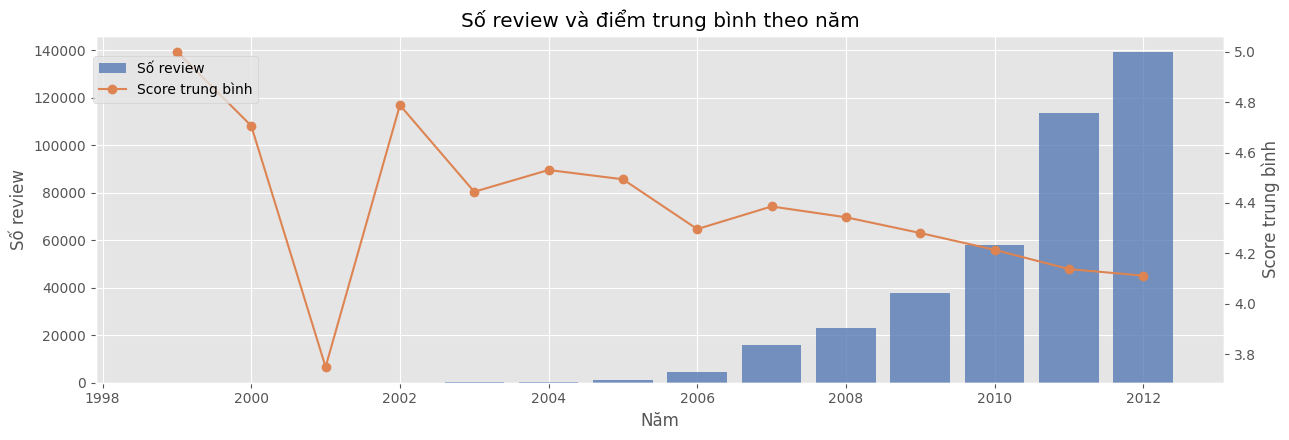

date,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012
n,4.0,17.000,8.00,33.000,99.000,439.000,1059.000,4722.000,15752.000,23098.000,37866.000,57967.000,113428.000,139085.000
mean_score,5.0,4.706,3.75,4.788,4.444,4.531,4.494,4.296,4.386,4.343,4.281,4.214,4.138,4.112
pct_neg,0.0,0.059,0.25,0.030,0.071,0.068,0.084,0.125,0.100,0.104,0.120,0.140,0.153,0.161


In [21]:
yearly = df.groupby(df['date'].dt.year).agg(n=('Score', 'size'), mean_score=('Score', 'mean'),
                                            pct_neg=('label', lambda s: (s == 0).mean()))
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.bar(yearly.index, yearly['n'], color='#4c72b0', alpha=.75, label='Số review')
ax1.set(xlabel='Năm', ylabel='Số review', title='Số review và điểm trung bình theo năm')
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly['mean_score'], 'o-', color='#dd8452', label='Score trung bình')
ax2.set_ylabel('Score trung bình')
ax2.grid(False)
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.88))
plt.tight_layout()
plt.show()
yearly.T.round(3)

**Nhận xét:** số review tăng mạnh từ 2006 (2011–2012 chiếm ≈2/3); điểm trung bình giảm từ 4,39 (2007) xuống 4,11 (2012), tỉ lệ negative tăng từ 10,0% lên 16,1%. Phân bố nhãn **thay đổi theo thời gian**, nhưng ta chia ngẫu nhiên nên điểm số không đo được hiệu năng trên review tương lai (hạn chế, xem 6.8).

## 2.4 Mức độ hữu ích (Helpfulness) theo số sao

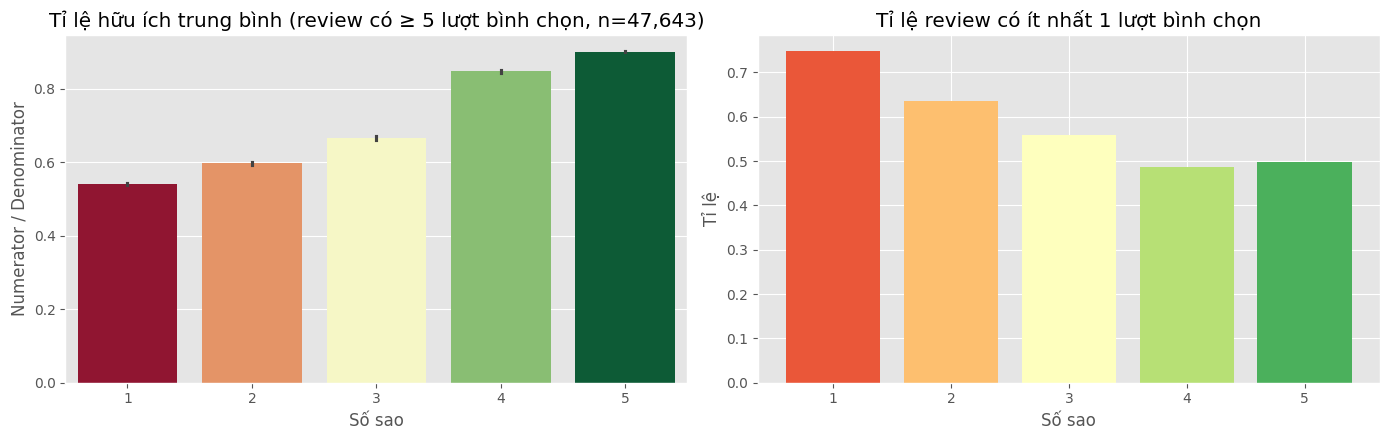

In [22]:
helpful = df[df['HelpfulnessDenominator'] >= 5].copy()
helpful['helpful_ratio'] = helpful['HelpfulnessNumerator'] / helpful['HelpfulnessDenominator']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=helpful, x='Score', y='helpful_ratio', hue='Score', palette='RdYlGn', legend=False, errorbar='se', ax=axes[0])
axes[0].set(title=f'Tỉ lệ hữu ích trung bình (review có ≥ 5 lượt bình chọn, n={len(helpful):,})',
            xlabel='Số sao', ylabel='Numerator / Denominator')
share = df.assign(has_vote=df['HelpfulnessDenominator'] > 0).groupby('Score')['has_vote'].mean()
axes[1].bar(share.index.astype(str), share.values, color=sns.color_palette('RdYlGn', 5))
axes[1].set(title='Tỉ lệ review có ít nhất 1 lượt bình chọn', xlabel='Số sao', ylabel='Tỉ lệ')
plt.tight_layout()
plt.show()

**Nhận xét:** review negative nhận nhiều bình chọn hơn nhưng ít được đánh giá hữu ích hơn. Helpfulness không có sẵn khi review vừa đăng nên **không** dùng làm đặc trưng.

## 2.5 Người dùng và sản phẩm

Số người dùng: 256,044 | Số sản phẩm: 67,554
Người dùng chỉ viết 1 review: 80.3% | Sản phẩm có ≤ 5 review: 78.7%


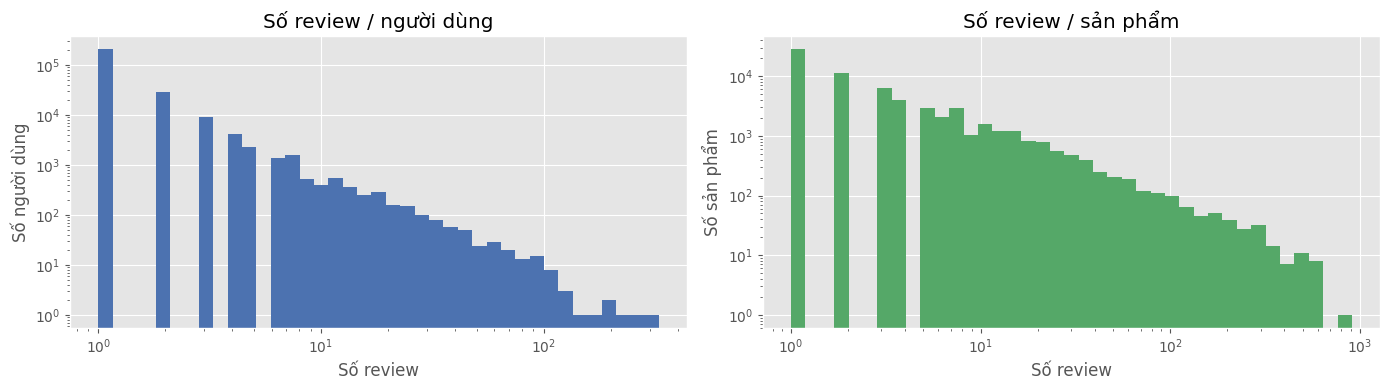

In [23]:
per_user = df['UserId'].value_counts()
per_product = df['ProductId'].value_counts()
print(f'Số người dùng: {per_user.size:,} | Số sản phẩm: {per_product.size:,}')
print(f'Người dùng chỉ viết 1 review: {(per_user == 1).mean():.1%} | Sản phẩm có ≤ 5 review: {(per_product <= 5).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(per_user.values, bins=np.logspace(0, np.log10(per_user.max() + 1), 40), color='#4c72b0')
axes[0].set(xscale='log', yscale='log', title='Số review / người dùng', xlabel='Số review', ylabel='Số người dùng')
axes[1].hist(per_product.values, bins=np.logspace(0, np.log10(per_product.max() + 1), 40), color='#55a868')
axes[1].set(xscale='log', yscale='log', title='Số review / sản phẩm', xlabel='Số review', ylabel='Số sản phẩm')
plt.tight_layout()
plt.show()

**Nhận xét:** cả hai phân bố đều đuôi dài (80,3% người dùng chỉ viết 1 review), nên mô hình phải học từ nội dung văn bản.

## 2.6 Nhiễu trong văn bản
Thẻ HTML, URL, ký tự HTML mã hoá. Hàm `clean_text` (`src/text.py`) được dùng lại ở Phần 3.

In [24]:
noise = pd.Series({
    'Chứa thẻ HTML (<br />, <a href...>)': df['Text'].str.contains(r'<[^>]+>', regex=True).mean(),
    'Chứa URL (http, www)': df['Text'].str.contains(r'http|www\.', regex=True).mean(),
    'Chứa ký tự HTML mã hoá (&amp; &quot; ...)': df['Text'].str.contains(r'&[a-z]+;', regex=True).mean(),
}, name='Tỉ lệ review').map('{:.2%}'.format)
display(noise.to_frame())

sample_html = df.loc[df['Text'].str.contains('<br', regex=False), 'Text'].iloc[0]
print('TRƯỚC:', sample_html[:400], '\n')
print('SAU  :', clean_text(sample_html)[:400])

,Tỉ lệ review
"Chứa thẻ HTML (<br />, <a href...>)",26.14%
"Chứa URL (http, www)",2.08%
Chứa ký tự HTML mã hoá (&amp; &quot; ...),0.33%


TRƯỚC: I don't know if it's the cactus or the tequila or just the unique combination of ingredients, but the flavour of this hot sauce makes it one of a kind!  We picked up a bottle once on a trip we were on and brought it back home with us and were totally blown away!  When we realized that we simply couldn't find it anywhere in our city we were bummed.<br /><br />Now, because of the magic of the intern 

SAU  : I don't know if it's the cactus or the tequila or just the unique combination of ingredients, but the flavour of this hot sauce makes it one of a kind! We picked up a bottle once on a trip we were on and brought it back home with us and were totally blown away! When we realized that we simply couldn't find it anywhere in our city we were bummed. Now, because of the magic of the internet, we have a


**Nhận xét:** ≈26% review chứa thẻ HTML. Chỉ làm sạch **nhẹ**, giữ dấu câu và từ phủ định (*not*, *no*, *never* quyết định cảm xúc).

## 2.7 Từ vựng đặc trưng của từng lớp
Unigram/bigram trên mẫu cân bằng giữa các lớp (bỏ stopword, giữ từ phủ định).

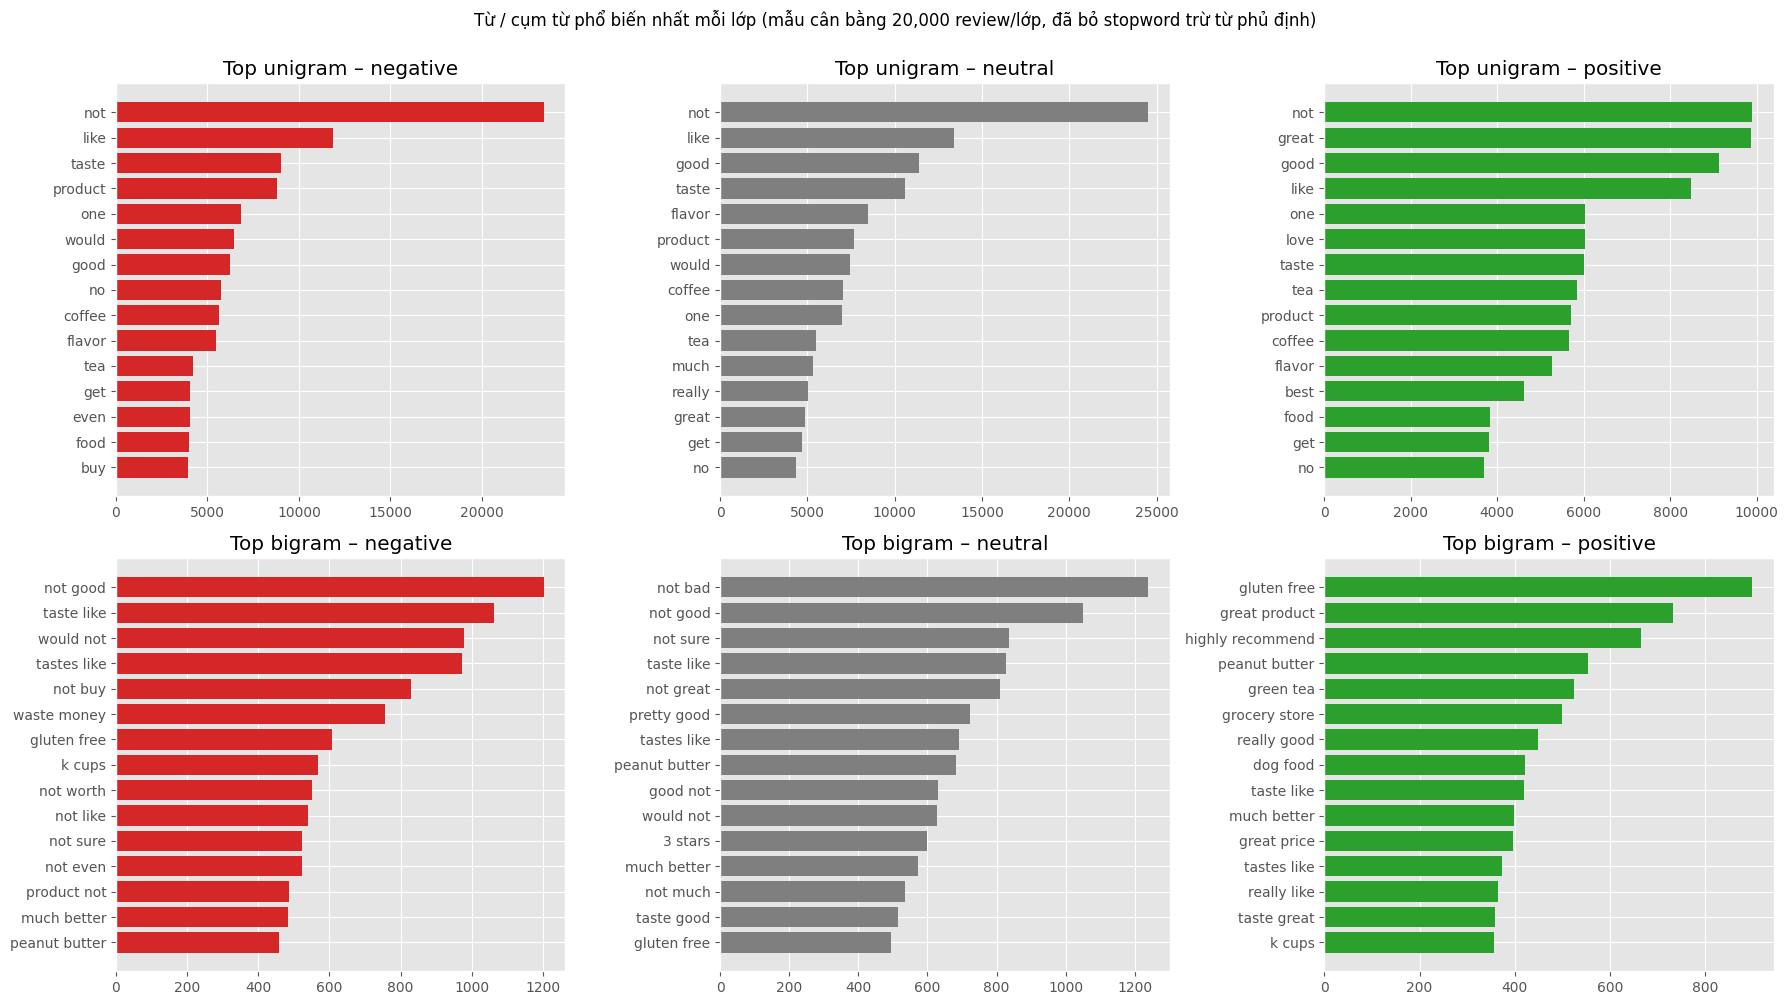

In [25]:
STOPWORDS = set(nltk.corpus.stopwords.words('english')) - NEGATIONS

n_per_class = min(20_000, df['label'].value_counts().min())
eda_sample = pd.concat([g.sample(n_per_class, random_state=SEED) for _, g in df.groupby('label')])
eda_tokens = [[w for w in tokenize(clean_text(t)) if w not in STOPWORDS and w.isalnum()]
              for t in eda_sample['Summary'] + ' ' + eda_sample['Text']]

def top_ngrams(token_lists, n, k=15):
    counter = Counter()
    for toks in token_lists:
        counter.update(' '.join(toks[i:i + n]) for i in range(len(toks) - n + 1))
    return pd.Series(dict(counter.most_common(k)))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, ngram in enumerate([1, 2]):
    for col, lab in enumerate(LABELS):
        toks = [t for t, s in zip(eda_tokens, eda_sample['sentiment']) if s == lab]
        s = top_ngrams(toks, ngram)
        axes[row, col].barh(s.index[::-1], s.values[::-1], color=PALETTE[lab])
        axes[row, col].set_title(f'Top {"unigram" if ngram == 1 else "bigram"} – {lab}')
plt.suptitle(f'Từ / cụm từ phổ biến nhất mỗi lớp (mẫu cân bằng {n_per_class:,} review/lớp, đã bỏ stopword trừ từ phủ định)', y=1.0)
plt.tight_layout()
plt.show()

**Nhận xét:** các từ như *good*, *taste*, *coffee* có ở cả 3 lớp; cặp từ phân biệt tốt hơn (*highly recommend* / *waste money*). Neutral không có từ vựng riêng nên dự kiến khó nhất.

## 2.8 Từ EDA đến quyết định thiết kế

| Phát hiện | Quyết định |
|---|---|
| ≈31% review trùng | Loại trùng **trước** khi chia (Phần 1) |
| Nhãn 78 / 14,5 / 7,6% | Chia phân tầng; trọng số lớp; Macro-F1 |
| Độ dài lệch phải | 200 từ (BiLSTM), 256 token (BERT); padding động + bucketing |
| Summary ngắn nhưng giàu cảm xúc | Đầu vào = `Summary` + `Text` |
| 26% có HTML | Làm sạch nhẹ, giữ dấu câu và phủ định |
| Ngữ cảnh và phủ định quan trọng | Mô hình chuỗi (BiLSTM) và Transformer (BERT) |

# Phần 3 · Chuẩn bị dữ liệu

**Đầu vào:** `reviews_clean.pkl`. **Đầu ra:** `train.pkl`, `val.pkl`, `test.pkl`, `class_weights.json`. Việc token hoá làm trong phần của từng mô hình.

In [26]:
import json
import time

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

from src.config import CFG, LABELS, SEED, setup_notebook
from src.data import CLASS_WEIGHTS_PATH, SPLIT_PATHS, load_clean
from src.text import build_input_text

setup_notebook()
df = load_clean()
if CFG['sample_size']:
    df = df.sample(n=CFG['sample_size'], random_state=SEED).reset_index(drop=True)
    print(f'QUICK_RUN: lấy mẫu {len(df):,} review')
print(f'{len(df):,} review')

PyTorch 2.14.1+cu130 | thiết bị: cuda (Tesla T4)
393,577 review


## 3.1 Tạo văn bản đầu vào
`text = clean(Summary) + ". " + clean(Text)`. Dấu chấm chỉ thêm khi Summary chưa kết thúc bằng `.`, `!` hoặc `?`.

In [27]:
t0 = time.time()
df['text'] = build_input_text(df['Summary'], df['Text'])
print(f'Làm sạch {len(df):,} review trong {time.time() - t0:.1f}s')
df[['Summary', 'Text', 'text', 'sentiment']].head(3)

Làm sạch 393,577 review trong 16.1s


,Summary,Text,text,sentiment
0,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labr...,Good Quality Dog Food. I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it...,positive
1,Not as Advertised,"Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as ""Jumbo"".",Not as Advertised. Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the produc...,negative
2,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then liberally coated with ...","""Delight"" says it all. This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then ...",positive


## 3.2 Chia train / validation / test (80/10/10, phân tầng theo nhãn)
Train cập nhật trọng số; validation chọn epoch, hệ số và ngưỡng; test chỉ dùng **một lần** ở cuối.

In [28]:
cols = ['text', 'label', 'Score']
train_df, temp_df = train_test_split(df[cols], test_size=0.2, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
test_df['n_words'] = test_df['text'].str.split().str.len()

split_summary = pd.DataFrame({name: d['label'].value_counts(normalize=True).reindex([0, 1, 2]).values
                              for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]},
                             index=LABELS).T
split_summary.insert(0, 'Số review', [len(train_df), len(val_df), len(test_df)])
display(split_summary.style.format({'Số review': '{:,}', **{l: '{:.2%}' for l in LABELS}}))

,Số review,negative,neutral,positive
train,"314,861",14.50%,7.56%,77.94%
val,"39,358",14.50%,7.56%,77.94%
test,"39,358",14.50%,7.56%,77.94%


## 3.3 Trọng số lớp
$w_c = N / (K \cdot N_c)$ với $K = 3$. Dùng cho cross-entropy có trọng số của BiLSTM và BERT; neutral nặng nhất (4,4×).

In [29]:
y_train = train_df['label'].values
class_counts = np.bincount(y_train, minlength=3)
class_weights = len(y_train) / (3 * class_counts)
pd.DataFrame({'Số mẫu train': class_counts, 'Trọng số': class_weights.round(3)}, index=LABELS)

,Số mẫu train,Trọng số
negative,45654,2.299
neutral,23803,4.409
positive,245404,0.428


## 3.4 Lưu kết quả

In [30]:
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    d.to_pickle(SPLIT_PATHS[name])
CLASS_WEIGHTS_PATH.write_text(json.dumps({'labels': LABELS, 'counts': class_counts.tolist(),
                                          'weights': class_weights.tolist()}, indent=2), encoding='utf-8')
for p in [*SPLIT_PATHS.values(), CLASS_WEIGHTS_PATH]:
    print('Đã lưu', p)

Đã lưu /content/drive/MyDrive/sentiment-analysis-project/outputs/data/train.pkl
Đã lưu /content/drive/MyDrive/sentiment-analysis-project/outputs/data/val.pkl
Đã lưu /content/drive/MyDrive/sentiment-analysis-project/outputs/data/test.pkl
Đã lưu /content/drive/MyDrive/sentiment-analysis-project/outputs/data/class_weights.json


# Phần 4 · BiLSTM + Attention (huấn luyện từ đầu)

**Đầu vào:** `train/val/test.pkl`, `class_weights.json`. **Đầu ra:** `outputs/bilstm/` và `outputs/predictions/bilstm_attention.*`. Đặt `RETRAIN = True` (Phần 0) để huấn luyện lại.

In [31]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

from src.config import BILSTM_DIR, CFG, DEVICE, LABELS, SEED, set_seed, setup_notebook
from src.data import Vocab, collate_lstm, load_class_weights, load_splits, make_loader
from src.evaluation import compute_metrics, plot_confusion, report, save_predictions
from src.explain import show_attention
from src.models import BiLSTMAttention, count_params
from src.text import tokenize
from src.training import fit_bilstm, predict_lstm

setup_notebook()

CKPT_PATH, VOCAB_PATH = BILSTM_DIR / 'model.pt', BILSTM_DIR / 'vocab.json'
HIST_PATH, INFO_PATH = BILSTM_DIR / 'history.csv', BILSTM_DIR / 'train_info.json'
TRAIN_MODEL = RETRAIN or not CKPT_PATH.exists()
print('Huấn luyện BiLSTM từ đầu' if TRAIN_MODEL else f'Đã có checkpoint -> nạp lại từ {CKPT_PATH}')

train_df, val_df, test_df = load_splits()
y_train, y_val, y_test = train_df['label'].values, val_df['label'].values, test_df['label'].values
CLASS_WEIGHTS_T = torch.tensor(load_class_weights(), device=DEVICE)
print(f'train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}')

PyTorch 2.14.1+cu130 | thiết bị: cuda (Tesla T4)
Đã có checkpoint -> nạp lại từ /content/drive/MyDrive/sentiment-analysis-project/outputs/bilstm/model.pt
train 314,861 | val 39,358 | test 39,358


## 4.1 Kiến trúc
`Embedding (V×128) → Dropout → BiLSTM (128/chiều) → Attention pooling → Dropout → Linear (256→3)`

- **BiLSTM** đọc câu theo hai chiều nên xử lý được phủ định ("not … good").
- **Attention pooling:** học trọng số $\alpha_t$ cho từng từ; vector câu là tổng có trọng số các trạng thái ẩn. $\alpha_t$ còn dùng để diễn giải (mục 4.7).
- Chống overfitting: dropout, weight decay, gradient clipping, early stopping theo Macro-F1 validation.

Code kiến trúc: `src/models.py`.

## 4.2 Token hoá và từ điển
Regex chữ thường, giữ dạng rút gọn (*don't*) và `!`, `?`. Từ điển ≤50.000 từ (xuất hiện ≥3 lần) chỉ từ tập **train**; từ lạ thành `<unk>`.

In [32]:
print(tokenize("Not as good as I expected... it's OK, but I won't buy it again!!"))

t0 = time.time()
train_tokens = [tokenize(t) for t in tqdm(train_df['text'], desc='Token hoá train', leave=False)]
val_tokens = [tokenize(t) for t in val_df['text']]
test_tokens = [tokenize(t) for t in test_df['text']]

if TRAIN_MODEL:
    vocab = Vocab.build(train_tokens, CFG['lstm_max_vocab'], CFG['lstm_min_freq'])
    vocab.save(VOCAB_PATH)
    counter = vocab.counter
else:
    vocab = Vocab.load(VOCAB_PATH)
    from collections import Counter
    counter = Counter(tok for toks in train_tokens for tok in toks)

MAX_LEN = CFG['lstm_max_len']
train_ids = [vocab.encode(t, MAX_LEN) for t in train_tokens]
val_ids = [vocab.encode(t, MAX_LEN) for t in val_tokens]
test_ids = [vocab.encode(t, MAX_LEN) for t in test_tokens]

covered = sum(c for w, c in counter.items() if w in vocab.stoi)
train_lens = np.array([len(t) for t in train_tokens])
print(f'Số từ khác nhau trong train: {len(counter):,} | kích thước từ điển: {len(vocab):,}')
print(f'Tỉ lệ token train nằm trong từ điển: {covered / sum(counter.values()):.2%}')
print(f'Tỉ lệ review bị cắt (> {MAX_LEN} token): {(train_lens > MAX_LEN).mean():.2%}')
print(f'Thời gian: {time.time() - t0:.0f}s')
print('Ví dụ mã hoá:', train_tokens[0][:12], '->', train_ids[0][:12])
del train_tokens, val_tokens, test_tokens, counter

['not', 'as', 'good', 'as', 'i', 'expected', "it's", 'ok', 'but', 'i', "won't", 'buy', 'it', 'again', '!', '!']


Token hoá train:   0%|          | 0/314861 [00:00<?, ?it/s]

Số từ khác nhau trong train: 111,480 | kích thước từ điển: 46,760
Tỉ lệ token train nằm trong từ điển: 99.71%
Tỉ lệ review bị cắt (> 200 token): 6.47%
Thời gian: 25s
Ví dụ mã hoá: ['tart', 'but', 'good', "izze's", 'all', 'natural', 'sparkling', 'pomegranate', 'juice', 'is', 'a', 'good'] -> [1176, 16, 28, 10230, 42, 234, 1968, 1427, 379, 9, 5, 28]


## 4.3 DataLoader với bucketing
`BucketBatchSampler` gom các câu cùng độ dài vào một batch để giảm padding; vị trí padding bị che (mask) trong attention. Không dùng `pack_padded_sequence` vì đo trên CPU nó chậm ≈9 lần (chưa đo lại trên GPU).

In [33]:
BS = CFG['lstm_batch_size']
train_loader = make_loader(train_ids, y_train, BS, shuffle=True, collate_fn=collate_lstm)
val_loader = make_loader(val_ids, y_val, BS, shuffle=False, collate_fn=collate_lstm)
test_loader = make_loader(test_ids, y_test, BS, shuffle=False, collate_fn=collate_lstm)
_, xb, lb, yb = next(iter(train_loader))
print(f'Số batch/epoch: {len(train_loader):,} | một batch: x={tuple(xb.shape)}, độ dài {lb.min().item()}–{lb.max().item()}')

Số batch/epoch: 1,230 | một batch: x=(256, 119), độ dài 113–119


## 4.4 Khởi tạo mô hình

In [34]:
set_seed(SEED)
lstm_model = BiLSTMAttention(len(vocab), CFG['lstm_emb_dim'], CFG['lstm_hidden'], CFG['lstm_layers'],
                             3, CFG['lstm_dropout']).to(DEVICE)
print(lstm_model)
n_params = count_params(lstm_model)
print(f'Số tham số huấn luyện được: {n_params:,}')
pd.Series({name: p.numel() for name, p in lstm_model.named_parameters()}, name='số tham số').to_frame()

BiLSTMAttention(
  (embedding): Embedding(46760, 128, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (attn): Linear(in_features=256, out_features=1, bias=True)
  (classifier): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=256, out_features=3, bias=True)
  )
)
Số tham số huấn luyện được: 6,250,500


,số tham số
embedding.weight,5985280
lstm.weight_ih_l0,65536
lstm.weight_hh_l0,65536
lstm.bias_ih_l0,512
lstm.bias_hh_l0,512
lstm.weight_ih_l0_reverse,65536
lstm.weight_hh_l0_reverse,65536
lstm.bias_ih_l0_reverse,512
lstm.bias_hh_l0_reverse,512
attn.weight,256


## 4.5 Huấn luyện
Cross-entropy có trọng số lớp; AdamW (lr 2e-3, weight decay 1e-4); `ReduceLROnPlateau` theo Macro-F1 validation; gradient clipping 1,0; early stopping `patience = 2`, giữ epoch tốt nhất.

In [35]:
criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS_T)

if TRAIN_MODEL:
    history, best_f1, train_time = fit_bilstm(
        lstm_model, train_loader, val_loader, y_val, criterion,
        epochs=CFG['lstm_epochs'], lr=CFG['lstm_lr'], patience=CFG['lstm_patience'], ckpt_path=CKPT_PATH)
    hist = pd.DataFrame(history)
    hist.to_csv(HIST_PATH, index=False)
    INFO_PATH.write_text(json.dumps({'train_time_s': train_time, 'best_val_macro_f1': best_f1}, indent=2))
else:
    lstm_model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
    hist = pd.read_csv(HIST_PATH) if HIST_PATH.exists() else None
    info = json.loads(INFO_PATH.read_text()) if INFO_PATH.exists() else {}
    train_time, best_f1 = info.get('train_time_s'), info.get('best_val_macro_f1', float('nan'))
    print(f'Đã nạp {CKPT_PATH}')
print(f'Thời gian huấn luyện: {(train_time or 0) / 60:.1f} phút | Macro-F1 validation tốt nhất: {best_f1:.4f}')

Đã nạp /content/drive/MyDrive/sentiment-analysis-project/outputs/bilstm/model.pt
Thời gian huấn luyện: 3.4 phút | Macro-F1 validation tốt nhất: 0.7504


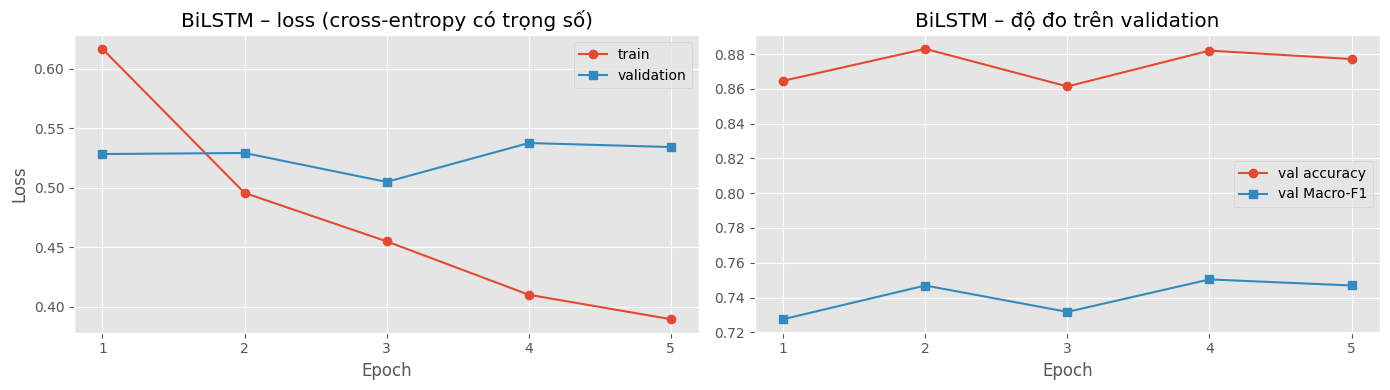

,epoch,train_loss,val_loss,val_acc,val_macro_f1,lr
0,1,0.6168,0.5283,0.8646,0.7275,0.002
1,2,0.4956,0.5292,0.8830,0.7469,0.002
2,3,0.4549,0.5049,0.8614,0.7318,0.002
3,4,0.4100,0.5376,0.8820,0.7504,0.001
4,5,0.3894,0.5342,0.8772,0.7469,0.001


In [36]:
if hist is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(hist['epoch'], hist['train_loss'], 'o-', label='train')
    axes[0].plot(hist['epoch'], hist['val_loss'], 's-', label='validation')
    axes[0].set(title='BiLSTM – loss (cross-entropy có trọng số)', xlabel='Epoch', ylabel='Loss')
    axes[0].legend()
    axes[1].plot(hist['epoch'], hist['val_acc'], 'o-', label='val accuracy')
    axes[1].plot(hist['epoch'], hist['val_macro_f1'], 's-', label='val Macro-F1')
    axes[1].set(title='BiLSTM – độ đo trên validation', xlabel='Epoch')
    axes[1].legend()
    for ax in axes:
        ax.xaxis.get_major_locator().set_params(integer=True)
    plt.tight_layout()
    plt.show()
    display(hist.round(4))

**Đường cong học:** train loss giảm đều (0,617 → 0,389) còn validation loss đi ngang quanh 0,53 (thấp nhất ở epoch 3), dấu hiệu overfitting từ epoch 3–4. Macro-F1 validation cao nhất ở epoch 4 (0,7504) nên giữ checkpoint này; chênh lệch giữa các epoch cuối chỉ khoảng 0,003.

## 4.6 Đánh giá trên tập test

=== BiLSTM + Attention ===  Accuracy = 0.8788 | Macro-F1 = 0.7422
              precision    recall  f1-score   support

    negative     0.8289    0.7479    0.7863      5707
     neutral     0.3862    0.6760    0.4916      2975
    positive     0.9761    0.9229    0.9488     30676

    accuracy                         0.8788     39358
   macro avg     0.7304    0.7822    0.7422     39358
weighted avg     0.9102    0.8788    0.8906     39358



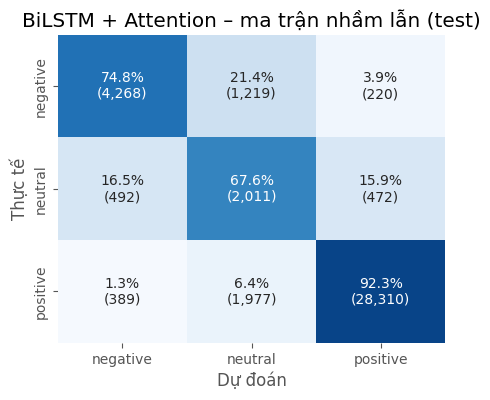

In [37]:
t0 = time.time()
test_probs, _ = predict_lstm(lstm_model, test_loader)
infer_time = time.time() - t0
test_pred = test_probs.argmax(1)
report('BiLSTM + Attention', y_test, test_pred)
plot_confusion(y_test, test_pred, 'BiLSTM + Attention – ma trận nhầm lẫn (test)')
plt.show()

save_predictions('BiLSTM + Attention', test_probs,
                 {'train_time_s': train_time, 'infer_time_s': infer_time, 'n_params': n_params})

## 4.7 Diễn giải: attention nhìn vào từ nào?
Màu đậm = trọng số attention lớn.

In [38]:
short = test_df[test_df['n_words'].between(15, 45)]
for lab in [0, 1, 2]:
    cand = short[(short['label'] == lab) & (test_pred[short.index] == lab)]
    if len(cand):
        show_attention(lstm_model, vocab, cand.iloc[0]['text'], MAX_LEN, lab)
show_attention(lstm_model, vocab, "I really wanted to like this coffee, but it tastes burnt and I will not buy it again.", MAX_LEN)

**Nhận xét:** attention thường dồn vào từ mang cảm xúc hoặc đảo nghĩa (*mistake*, *great*, *not*, *okay*, *but*), nhưng không phải luôn vậy: ở ví dụ neutral đầu tiên từ nặng nhất là *stevia*, một tên sản phẩm. Attention chỉ gợi ý mô hình nhìn vào đâu, không phải lời giải thích đầy đủ.

# Phần 5 · Fine-tune BERT-base (học chuyển giao)

**Đầu vào:** `train/val/test.pkl`, `class_weights.json`. **Đầu ra:** `outputs/bert/` và `outputs/predictions/bert_fine_tune.*`. Đặt `RETRAIN = True` để fine-tune lại (≈64 phút trên T4).

In [39]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

from src.config import CFG, DEVICE, BERT_DIR, LABELS, ON_GPU, SEED, set_seed, setup_notebook
from src.data import load_class_weights, load_splits, make_collate_transformer, make_loader
from src.evaluation import plot_confusion, predict_transformer, report, save_predictions
from src.models import count_params

setup_notebook()

HIST_PATH, STEPS_PATH, INFO_PATH = BERT_DIR / 'history.csv', BERT_DIR / 'step_losses.npy', BERT_DIR / 'train_info.json'
TRAIN_MODEL = RETRAIN or not (BERT_DIR / 'config.json').exists()
print('Fine-tune BERT' if TRAIN_MODEL else f'Đã có mô hình -> nạp lại từ {BERT_DIR}')

train_df, val_df, test_df = load_splits()
y_test = test_df['label'].values
CLASS_WEIGHTS_T = torch.tensor(load_class_weights(), device=DEVICE)
MAX_LEN = CFG['trf_max_len']

PyTorch 2.14.1+cu130 | thiết bị: cuda (Tesla T4)
Đã có mô hình -> nạp lại từ /content/drive/MyDrive/sentiment-analysis-project/outputs/bert


## 5.1 Ý tưởng
**BERT-base** (`bert-base-uncased`): Transformer encoder 12 lớp, 109 triệu tham số, tiền huấn luyện trên Wikipedia + BookCorpus. Fine-tune: thêm lớp phân loại 3 nhãn lên token `[CLS]` rồi huấn luyện toàn mạng với learning rate nhỏ (3e-5), warmup 10% rồi giảm tuyến tính, AdamW, cross-entropy có trọng số lớp. Tokenizer WordPiece; self-attention cho mỗi token nhìn trực tiếp mọi token khác.

Có **GPU**: toàn bộ tập train, 256 token. Chỉ có **CPU**: tập con 20.000 review, 128 token (không so sánh được với Phần 6). Lần chạy báo cáo: T4, 314.861 review, 2 epoch, 64,4 phút. Luôn đánh giá trên **toàn bộ** tập test.

## 5.2 Dữ liệu và token hoá WordPiece

In [40]:
def stratified_subset(frame, n):
    if n is None or n >= len(frame):
        return frame.reset_index(drop=True)
    return train_test_split(frame, train_size=n, stratify=frame['label'], random_state=SEED)[0].reset_index(drop=True)

trf_train = stratified_subset(train_df, CFG['trf_train_size'])
trf_val = stratified_subset(val_df, CFG['trf_val_size'])
tokenizer = AutoTokenizer.from_pretrained(CFG['trf_name'] if TRAIN_MODEL else BERT_DIR)

print(f'Fine-tune trên {len(trf_train):,} review train, chọn epoch theo {len(trf_val):,} review validation, max_len = {MAX_LEN} token')
print('Ví dụ WordPiece:', tokenizer.tokenize("The unbelievably crunchy granola wasn't overpriced!"))
sub_lens = np.array([len(x) for x in tokenizer(list(trf_train['text'].sample(min(3000, len(trf_train)), random_state=SEED)))['input_ids']])
print(f'Độ dài subword: trung vị {np.median(sub_lens):.0f}, p90 {np.percentile(sub_lens, 90):.0f} '
      f'| tỉ lệ bị cắt ở {MAX_LEN}: {(sub_lens > MAX_LEN).mean():.1%}')

Fine-tune trên 314,861 review train, chọn epoch theo 39,358 review validation, max_len = 256 token
Ví dụ WordPiece: ['the', 'un', '##bel', '##ie', '##va', '##bly', 'crunch', '##y', 'gran', '##ola', 'wasn', "'", 't', 'over', '##pr', '##ice', '##d', '!']
Độ dài subword: trung vị 80, p90 207 | tỉ lệ bị cắt ở 256: 6.2%


In [41]:
t0 = time.time()
train_ids = tokenizer(list(trf_train['text']), truncation=True, max_length=MAX_LEN)['input_ids']
print(f'Token hoá xong trong {time.time() - t0:.0f}s')

collate_trf = make_collate_transformer(tokenizer.pad_token_id)
train_loader = make_loader(train_ids, trf_train['label'].values, CFG['trf_batch_size'], shuffle=True, collate_fn=collate_trf)
_, ids_b, mask_b, _ = next(iter(train_loader))
print(f'Số batch/epoch: {len(train_loader):,} | một batch: input_ids={tuple(ids_b.shape)}, attention_mask={tuple(mask_b.shape)}')

Token hoá xong trong 105s
Số batch/epoch: 9,840 | một batch: input_ids=(32, 58), attention_mask=(32, 58)


## 5.3 Khởi tạo mô hình và optimizer
Weight decay không áp cho bias và LayerNorm; fp16 chỉ bật khi có GPU.

In [42]:
set_seed(SEED)
if TRAIN_MODEL:
    model = AutoModelForSequenceClassification.from_pretrained(
        CFG['trf_name'], num_labels=3, id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)}).to(DEVICE)
else:
    model = AutoModelForSequenceClassification.from_pretrained(BERT_DIR).to(DEVICE)
n_params = count_params(model)
print(f'Số tham số: {n_params:,}')

no_decay = ['bias', 'LayerNorm.weight']
param_groups = [
    {'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], 'weight_decay': CFG['trf_weight_decay']},
    {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], 'weight_decay': 0.0},
]
optimizer = torch.optim.AdamW(param_groups, lr=CFG['trf_lr'])
total_steps = len(train_loader) * CFG['trf_epochs']
scheduler = get_linear_schedule_with_warmup(optimizer, int(CFG['trf_warmup'] * total_steps), total_steps)
criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS_T)
scaler = torch.amp.GradScaler('cuda', enabled=ON_GPU)
print(f'{len(train_loader):,} bước/epoch x {CFG["trf_epochs"]} epoch = {total_steps:,} bước')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Số tham số: 109,484,547
9,840 bước/epoch x 2 epoch = 19,680 bước


## 5.4 Fine-tune
Sau mỗi epoch chấm Macro-F1 validation và lưu ngay nếu là epoch tốt nhất. Không có early stopping.

In [43]:
if TRAIN_MODEL:
    history, step_losses = [], []
    best_f1 = -1.0
    t_start = time.time()
    for epoch in range(1, CFG['trf_epochs'] + 1):
        t0 = time.time()
        model.train()
        for _, input_ids, attention_mask, y in tqdm(train_loader, desc=f'epoch {epoch}', leave=False):
            input_ids, attention_mask, y = input_ids.to(DEVICE), attention_mask.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=ON_GPU):
                logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step_losses.append(loss.item())

        val_pred = predict_transformer(model, tokenizer, trf_val['text'], MAX_LEN, desc='validation').argmax(1)
        val_acc, val_f1 = accuracy_score(trf_val['label'], val_pred), f1_score(trf_val['label'], val_pred, average='macro')
        epoch_loss = np.mean(step_losses[-len(train_loader):])
        history.append({'epoch': epoch, 'train_loss': epoch_loss, 'val_acc': val_acc, 'val_macro_f1': val_f1})
        print(f'Epoch {epoch}: train_loss={epoch_loss:.4f} | val_acc={val_acc:.4f} | val_macro_F1={val_f1:.4f} | {(time.time() - t0) / 60:.1f} phút')
        if val_f1 > best_f1:
            best_f1 = val_f1
            model.save_pretrained(BERT_DIR)
            tokenizer.save_pretrained(BERT_DIR)
        pd.DataFrame(history).to_csv(HIST_PATH, index=False)
        torch.cuda.empty_cache()
    train_time = time.time() - t_start
    model = AutoModelForSequenceClassification.from_pretrained(BERT_DIR).to(DEVICE)
    hist = pd.DataFrame(history)
    hist.to_csv(HIST_PATH, index=False)
    np.save(STEPS_PATH, np.array(step_losses))
    INFO_PATH.write_text(json.dumps({'train_time_s': train_time, 'best_val_macro_f1': best_f1,
                                     'n_train': len(trf_train), 'max_len': MAX_LEN}, indent=2))
else:
    hist = pd.read_csv(HIST_PATH) if HIST_PATH.exists() else None
    step_losses = np.load(STEPS_PATH).tolist() if STEPS_PATH.exists() else []
    info = json.loads(INFO_PATH.read_text()) if INFO_PATH.exists() else {}
    train_time, best_f1 = info.get('train_time_s'), info.get('best_val_macro_f1', float('nan'))
    print(f'Đã nạp {BERT_DIR}')
print(f'Thời gian fine-tune: {(train_time or 0) / 60:.1f} phút | Macro-F1 validation tốt nhất: {best_f1:.4f}')

Đã nạp /content/drive/MyDrive/sentiment-analysis-project/outputs/bert
Thời gian fine-tune: 64.4 phút | Macro-F1 validation tốt nhất: 0.7864


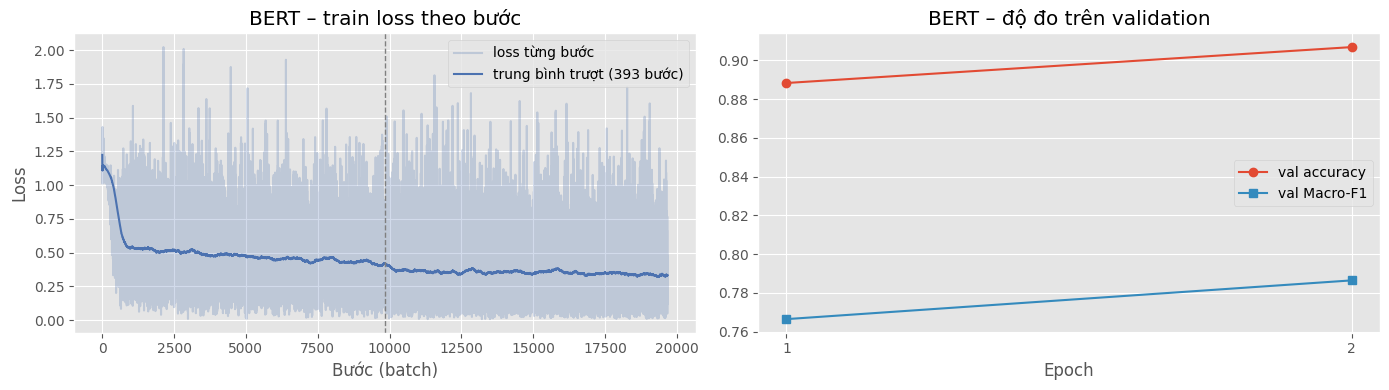

,epoch,train_loss,val_acc,val_macro_f1
0,1,0.4943,0.8884,0.7664
1,2,0.3517,0.9069,0.7864


In [44]:
if hist is not None and len(step_losses):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    window = max(1, len(step_losses) // 50)
    axes[0].plot(step_losses, alpha=.25, color='#4c72b0', label='loss từng bước')
    axes[0].plot(pd.Series(step_losses).rolling(window, min_periods=1).mean(), color='#4c72b0', label=f'trung bình trượt ({window} bước)')
    steps_per_epoch = len(step_losses) // len(hist)
    for e in range(1, len(hist)):
        axes[0].axvline(e * steps_per_epoch, ls='--', color='gray', lw=1)
    axes[0].set(title='BERT – train loss theo bước', xlabel='Bước (batch)', ylabel='Loss')
    axes[0].legend()
    axes[1].plot(hist['epoch'], hist['val_acc'], 'o-', label='val accuracy')
    axes[1].plot(hist['epoch'], hist['val_macro_f1'], 's-', label='val Macro-F1')
    axes[1].set(title='BERT – độ đo trên validation', xlabel='Epoch')
    axes[1].xaxis.get_major_locator().set_params(integer=True)
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    display(hist.round(4))

**Đường cong học:** train loss giảm 0,494 → 0,352; Macro-F1 validation tăng 0,7664 → 0,7864 và **vẫn đang tăng** ở epoch cuối, nên mô hình chưa bão hoà (thêm epoch có thể tốt hơn, ≈32 phút/epoch trên T4).

## 5.5 Đánh giá trên tập test

BERT test:   0%|          | 0/308 [00:00<?, ?it/s]

=== BERT fine-tune ===  Accuracy = 0.9074 | Macro-F1 = 0.7877
              precision    recall  f1-score   support

    negative     0.8486    0.8455    0.8470      5707
     neutral     0.4667    0.6813    0.5540      2975
    positive     0.9841    0.9409    0.9620     30676

    accuracy                         0.9074     39358
   macro avg     0.7665    0.8226    0.7877     39358
weighted avg     0.9254    0.9074    0.9145     39358



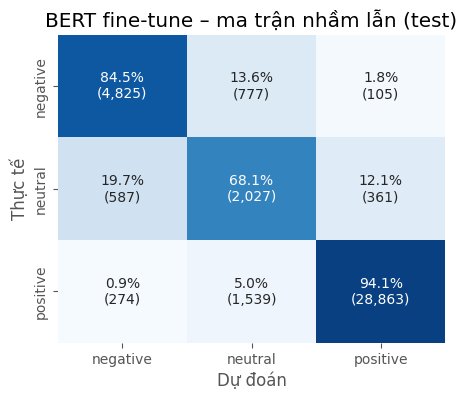

In [45]:
t0 = time.time()
test_probs = predict_transformer(model, tokenizer, test_df['text'], MAX_LEN,
                                 batch_size=128 if ON_GPU else 64, desc='BERT test')
infer_time = time.time() - t0
test_pred = test_probs.argmax(1)
report('BERT fine-tune', y_test, test_pred)
plot_confusion(y_test, test_pred, 'BERT fine-tune – ma trận nhầm lẫn (test)')
plt.show()

save_predictions('BERT fine-tune', test_probs,
                 {'train_time_s': train_time, 'infer_time_s': infer_time, 'n_params': n_params})

# Phần 6 · Đánh giá và so sánh

**Đầu vào:** `val/test.pkl`, `outputs/predictions/`, mô hình trong `outputs/`. **Đầu ra:** `outputs/results_test.csv`.

6.1 nạp dự đoán · 6.2 kết quả toàn bộ test · 6.3 theo độ dài · 6.4 phân tích lỗi · 6.5 bootstrap · 6.6 hiệu chỉnh ngưỡng neutral · 6.7 câu tự viết · 6.8 kết luận.

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from src.config import BERT_DIR, BILSTM_DIR, CFG, DEVICE, LABELS, ON_GPU, OUTPUT_DIR, PALETTE, setup_notebook
from src.data import Vocab, load_splits
from src.evaluation import (METRIC_COLS, bootstrap_macro_f1, compute_metrics, confusion_table, load_predictions,
                            paired_difference, plot_confusion, predict_lstm_probs, predict_transformer,
                            predict_with_neutral_bias, summarize_bootstrap, tune_neutral_bias)
from src.explain import lstm_predict_texts, show_attention
from src.models import BiLSTMAttention
from src.text import clean_text

setup_notebook()
_, val_df, test_df = load_splits()
y_val, y_test = val_df['label'].values, test_df['label'].values
print(f'test: {len(test_df):,} review')

PyTorch 2.14.1+cu130 | thiết bị: cuda (Tesla T4)
test: 39,358 review


## 6.1 Nạp dự đoán
Chỉ dùng dự đoán của BERT fine-tune và BiLSTM; thêm mốc **"Luôn đoán positive"**.

In [47]:
PRED = {k: v for k, v in load_predictions().items() if k in ('BERT fine-tune', 'BiLSTM + Attention')}
PRED['Luôn đoán positive'] = {'probs': np.tile([0., 0., 1.], (len(test_df), 1)), 'test_index': None,
                              'train_time_s': 0, 'infer_time_s': 0, 'n_params': 0}

full_models = list(PRED)
for name, p in PRED.items():
    p['pred'] = p['probs'].argmax(1)
    print(f'{name:22s} dự đoán trên toàn bộ test')

BERT fine-tune         dự đoán trên toàn bộ test
BiLSTM + Attention     dự đoán trên toàn bộ test
Luôn đoán positive     dự đoán trên toàn bộ test


## 6.2 Kết quả trên toàn bộ tập test

In [48]:
rows = {}
for name in full_models:
    p = PRED[name]
    rows[name] = {**compute_metrics(y_test, p['pred']),
                  'Train (s)': p['train_time_s'], 'Suy luận (s)': p['infer_time_s'], 'Số tham số': p['n_params']}
results_df = pd.DataFrame(rows).T.sort_values('Macro-F1', ascending=False)
display(results_df.style
        .format({**{c: '{:.4f}' for c in METRIC_COLS}, 'Train (s)': '{:,.0f}', 'Suy luận (s)': '{:,.1f}', 'Số tham số': '{:,.0f}'}, na_rep='–')
        .highlight_max(subset=METRIC_COLS, color='#c7e9c0')
        .set_caption(f'Kết quả trên tập test (n = {len(y_test):,})'))
results_df.to_csv(OUTPUT_DIR / 'results_test.csv')

,Accuracy,Macro-F1,Weighted-F1,F1 negative,F1 neutral,F1 positive,Train (s),Suy luận (s),Số tham số
BERT fine-tune,0.9074,0.7877,0.9145,0.8470,0.5540,0.9620,"3,867",83.7,"109,484,547"
BiLSTM + Attention,0.8788,0.7422,0.8906,0.7863,0.4916,0.9488,203,3.7,"6,250,500"
Luôn đoán positive,0.7794,0.2920,0.6828,0.0000,0.0000,0.8760,0,0.0,0


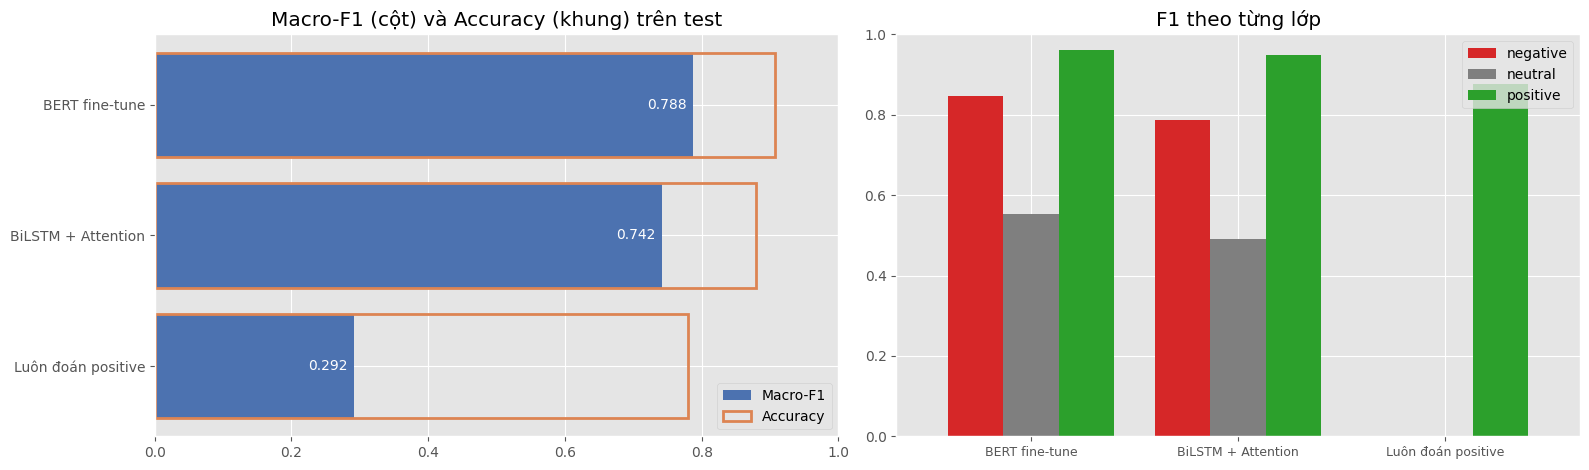

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
order = results_df['Macro-F1'].sort_values().index
axes[0].barh(order, results_df.loc[order, 'Macro-F1'], color='#4c72b0', label='Macro-F1')
axes[0].barh(order, results_df.loc[order, 'Accuracy'], color='none', edgecolor='#dd8452', lw=2, label='Accuracy')
for i, name in enumerate(order):
    axes[0].text(results_df.loc[name, 'Macro-F1'] - 0.01, i, f'{results_df.loc[name, "Macro-F1"]:.3f}', va='center', ha='right', color='white', fontsize=10)
axes[0].set(xlim=(0, 1), title='Macro-F1 (cột) và Accuracy (khung) trên test')
axes[0].legend(loc='lower right')

per_class = results_df.loc[order[::-1], ['F1 negative', 'F1 neutral', 'F1 positive']]
per_class.columns = LABELS
per_class.plot(kind='bar', ax=axes[1], color=[PALETTE[l] for l in LABELS], rot=0, width=0.8)
axes[1].set(title='F1 theo từng lớp', ylim=(0, 1))
axes[1].tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.show()

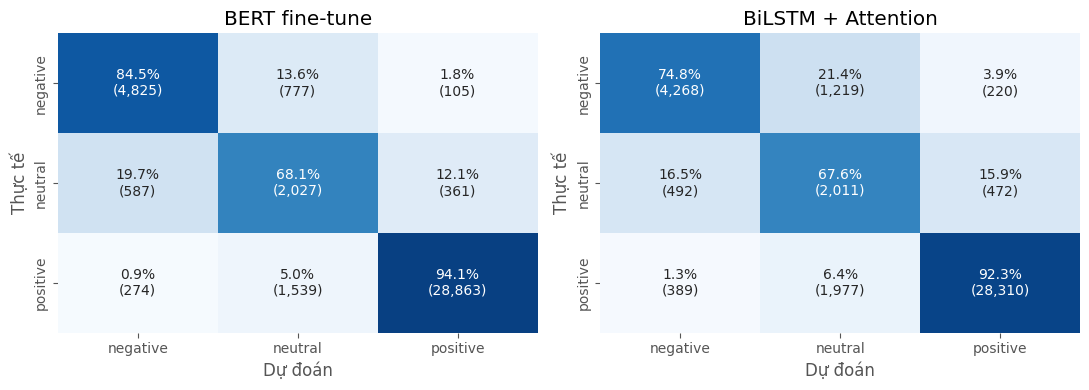

In [50]:
dl_models = [n for n in full_models if n != 'Luôn đoán positive']
fig, axes = plt.subplots(1, len(dl_models), figsize=(5.5 * len(dl_models), 4))
for ax, name in zip(np.atleast_1d(axes), dl_models):
    plot_confusion(y_test, PRED[name]['pred'], name, ax=ax)
plt.tight_layout()
plt.show()

In [51]:
for name in dl_models:
    display(confusion_table(y_test, PRED[name]['pred']).set_caption(f'{name}: ma trận nhầm lẫn chuẩn hoá theo hàng (test)'))
for name in dl_models:
    cm = confusion_matrix(y_test, PRED[name]['pred'], labels=[0, 1, 2])
    recall_row, precision_col = cm[1] / cm[1].sum(), cm[:, 1] / cm[:, 1].sum()
    print(f'{name}:')
    print(f'  Review neutral thật được đoán: đúng {recall_row[1]:.1%} | sang negative {recall_row[0]:.1%} | sang positive {recall_row[2]:.1%}')
    print(f'  Review bị đoán là neutral thật ra là: neutral {precision_col[1]:.1%} | negative {precision_col[0]:.1%} | positive {precision_col[2]:.1%}')

,đoán: negative,đoán: neutral,đoán: positive
thật: negative,84.5%,13.6%,1.8%
thật: neutral,19.7%,68.1%,12.1%
thật: positive,0.9%,5.0%,94.1%


,đoán: negative,đoán: neutral,đoán: positive
thật: negative,74.8%,21.4%,3.9%
thật: neutral,16.5%,67.6%,15.9%
thật: positive,1.3%,6.4%,92.3%


BERT fine-tune:
  Review neutral thật được đoán: đúng 68.1% | sang negative 19.7% | sang positive 12.1%
  Review bị đoán là neutral thật ra là: neutral 46.7% | negative 17.9% | positive 35.4%
BiLSTM + Attention:
  Review neutral thật được đoán: đúng 67.6% | sang negative 16.5% | sang positive 15.9%
  Review bị đoán là neutral thật ra là: neutral 38.6% | negative 23.4% | positive 38.0%


**Nhận xét (39.358 review test):**
- Cả hai mạng vượt xa mốc "luôn đoán positive" (Macro-F1 0,292): BiLSTM 0,742, BERT-base 0,788.
- **Học chuyển giao tốt hơn học từ đầu:** BERT-base hơn BiLSTM 0,0455 Macro-F1 và 2,9 điểm Accuracy, ở cả ba lớp (negative +0,061, neutral +0,062, positive +0,013). Mức chênh được kiểm ở mục 6.5.
- **Neutral khó nhất:** precision thấp (0,467 BERT; 0,386 BiLSTM), recall cao (≈0,68): mô hình đoán neutral quá nhiều, có thể do trọng số lớp 4,4×. Mục 6.6 thử bù bằng cách chỉnh ngưỡng.
- **Chi phí:** BERT-base ≈19× thời gian huấn luyện, 23× thời gian suy luận và 17,5× số tham số của BiLSTM; BiLSTM đạt ≈94% Macro-F1 của BERT với ≈5% thời gian huấn luyện.

## 6.3 Hiệu năng theo độ dài review

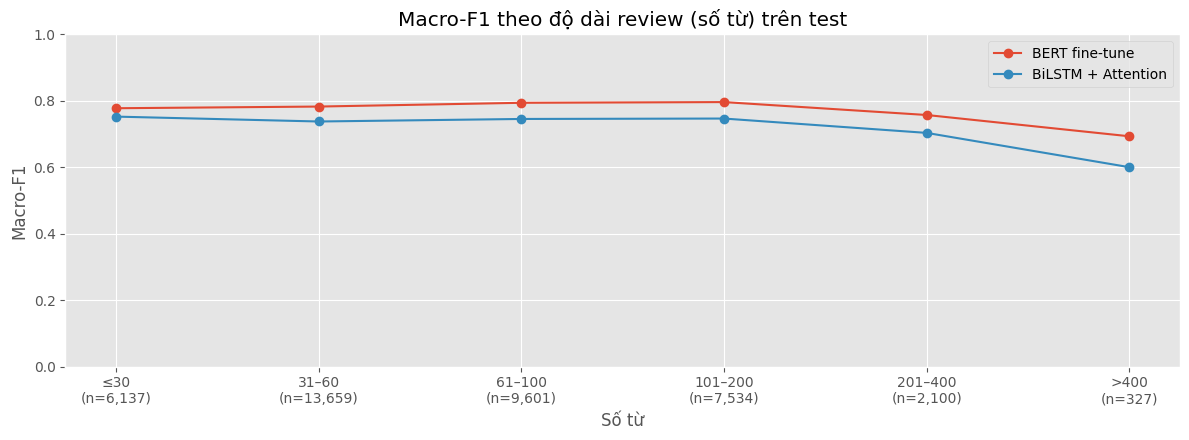

In [52]:
from sklearn.metrics import f1_score

bins = [0, 30, 60, 100, 200, 400, np.inf]
bucket_names = ['≤30', '31–60', '61–100', '101–200', '201–400', '>400']
test_df['len_bucket'] = pd.cut(test_df['n_words'], bins=bins, labels=bucket_names)
bucket_masks = [(test_df['len_bucket'] == b).values for b in bucket_names]
by_len = pd.DataFrame({name: [f1_score(y_test[m], PRED[name]['pred'][m], average='macro') if m.any() else np.nan
                              for m in bucket_masks] for name in dl_models}, index=bucket_names)
counts = test_df['len_bucket'].value_counts().reindex(bucket_names)

fig, ax = plt.subplots(figsize=(12, 4.5))
for name in by_len.columns:
    ax.plot(bucket_names, by_len[name], 'o-', label=name)
ax.set(title='Macro-F1 theo độ dài review (số từ) trên test', xlabel='Số từ', ylabel='Macro-F1', ylim=(0, 1))
ax.set_xticks(range(len(bucket_names)))
ax.set_xticklabels([f'{b}\n(n={c:,})' for b, c in zip(bucket_names, counts)])
ax.legend()
plt.tight_layout()
plt.show()

In [53]:
display(by_len.round(3).style.set_caption('Macro-F1 theo nhóm độ dài (số từ)'))
for name in by_len.columns:
    valid = by_len[name].dropna()
    print(f'{name}: tốt nhất ở nhóm "{valid.idxmax()}" ({valid.max():.3f}), kém nhất ở nhóm "{valid.idxmin()}" ({valid.min():.3f})')
print('Số review mỗi nhóm:', counts.to_dict())

,BERT fine-tune,BiLSTM + Attention
≤30,0.778000,0.753000
31–60,0.783000,0.738000
61–100,0.794000,0.746000
101–200,0.796000,0.747000
201–400,0.758000,0.704000
>400,0.693000,0.600000


BERT fine-tune: tốt nhất ở nhóm "101–200" (0.796), kém nhất ở nhóm ">400" (0.693)
BiLSTM + Attention: tốt nhất ở nhóm "≤30" (0.753), kém nhất ở nhóm ">400" (0.600)
Số review mỗi nhóm: {'≤30': 6137, '31–60': 13659, '61–100': 9601, '101–200': 7534, '201–400': 2100, '>400': 327}


**Cách đọc:** chú ý số review mỗi nhóm; nhóm >400 từ chỉ có 327 review nên dao động nhiều. Mọi mô hình thấp nhất ở nhóm >400 từ; BiLSTM giảm mạnh nhất (0,600 so với 0,693 của BERT-base), có thể vì cắt ở 200 từ (BERT: 256 token).

## 6.4 Phân tích lỗi của mô hình tốt nhất
Xem các review mà mô hình tốt nhất đoán sai với độ tự tin cao.

In [54]:
best_name = max(dl_models, key=lambda n: results_df.loc[n, 'Macro-F1'])
print('Mô hình tốt nhất:', best_name)
err = test_df[['text', 'Score', 'label']].copy()
err['pred'] = PRED[best_name]['pred']
err['confidence'] = PRED[best_name]['probs'].max(1)

def show_errors(mask, title, k=3):
    rows = err[mask].sort_values('confidence', ascending=False).head(k)
    print(f'\n### {title}  ({mask.sum():,} trường hợp)')
    for _, r in rows.iterrows():
        print(f'- [{r.Score}★ | thực tế: {LABELS[r.label]} | dự đoán: {LABELS[r.pred]} ({r.confidence:.0%})] {r.text[:350]}')

show_errors((err['Score'] == 5) & (err['pred'] == 0), 'Review 5 sao bị dự đoán NEGATIVE')
show_errors((err['Score'] == 1) & (err['pred'] == 2), 'Review 1 sao bị dự đoán POSITIVE')
show_errors((err['label'] == 1) & (err['pred'] != 1), 'Review 3 sao (neutral) bị dự đoán sai')

Mô hình tốt nhất: BERT fine-tune

### Review 5 sao bị dự đoán NEGATIVE  (165 trường hợp)
- [5★ | thực tế: positive | dự đoán: negative (100%)] Jamaican Panama Blue. Ordered coffee for a few months. Now I would not recommend it to my worst enemy. The coffee now has no aroma, is light brown and taste worse than ___________. (fill in the blank)
- [5★ | thực tế: positive | dự đoán: negative (100%)] Incredibly overpriced. I love mate, in all its forms. i especially love this brand, despite the stems in it. however this is a total and complete rip off for this product. I used to buy the 2.2 kg bags for $6.00 each before I moved to a town with only one specialty tea shop. Just wanted the general public to know that if you buy this for this price
- [5★ | thực tế: positive | dự đoán: negative (99%)] My dogs won't eat anything else. My dogs will not eat anything but the Iams biscuit. I have tried other biscuits but my dogs juat walked away from them.

### Review 1 sao bị dự đoán POSITIVE  (58 tr

**Nhận xét:** BERT-base đoán **165** review 5 sao là negative và **58** review 1 sao là positive. Nhiều ca tự tin nhất trông như **nhãn nhiễu** (chấm 5 sao nhưng viết lời chê, hoặc ngược lại): khi đó mô hình đọc văn bản đúng hơn số sao. Không phải ca nào cũng vậy (*"My dogs won't eat anything else…"* là lời khen bị đọc sai). Lỗi ở neutral (948 review) chủ yếu là review vừa khen vừa chê, ranh giới 3 sao với 2/4 sao vốn chủ quan. Ô dưới in thêm 15 ca **ngẫu nhiên** để đọc và đếm tỉ lệ nhãn nhiễu thật sự.

In [55]:
def sample_errors(mask, title, k=15, seed=0):
    rows = err[mask].sample(min(k, int(mask.sum())), random_state=seed)
    print(f'\n### {title}  (tổng {mask.sum():,} ca, in {len(rows)} ca ngẫu nhiên)')
    for _, r in rows.iterrows():
        print(f'- [{r.Score}★ | dự đoán: {LABELS[r.pred]} ({r.confidence:.0%})] {r.text[:260]}')

sample_errors((err['Score'] == 5) & (err['pred'] == 0), 'Review 5 sao bị dự đoán NEGATIVE')
sample_errors((err['Score'] == 1) & (err['pred'] == 2), 'Review 1 sao bị dự đoán POSITIVE')


### Review 5 sao bị dự đoán NEGATIVE  (tổng 165 ca, in 15 ca ngẫu nhiên)
- [5★ | dự đoán: negative (88%)] Call Keurig before you buy this! If you call Keurig and let them know you lost this item or it got damaged somehow, they will send you a replacement for free, whether you are on warranty or not. Because they don't sell this item individually, they send it to y
- [5★ | dự đoán: negative (50%)] Candy or gum? I have a vague memory of the package asking us to send in an essay saying whether Razzles was a candy or a gum (early 70's).
- [5★ | dự đoán: negative (95%)] Do not buy Keurig, you are only helping them. Apparently, I am unhappy with the price jolt of this coffee, which I use daily. I am even more unhappy with the discontinuation of the coffee makers and the fact that the coffee pods can only be found on Amazon or 
- [5★ | dự đoán: negative (98%)] Nothing else works. I understand all the complaints about Science Diet. Believe me I avoided this food for quite awhile based on that

**Việc cần làm:** đọc các ca ngẫu nhiên, đếm bao nhiêu là nhãn nhiễu so với mô hình đọc sai (mỉa mai, phủ định phức tạp) và ghi tỉ lệ vào báo cáo.

## 6.5 Khoảng tin cậy (bootstrap) cho Macro-F1
Lấy mẫu có hoàn lại tập test 1.000 lần, tính Macro-F1 của mọi mô hình trên **cùng** một mẫu rồi lấy khoảng giữa 95%; cũng tính khoảng cho **chênh lệch** giữa hai mô hình. Khoảng này chỉ phản ánh sai số do tập test, không phản ánh sai số do seed (mỗi mô hình chỉ chạy một seed).

In [56]:
point = {n: PRED[n]['pred'] for n in full_models}
boot = bootstrap_macro_f1(y_test, point, n_boot=1000)
ci = summarize_bootstrap(boot, {n: results_df.loc[n, 'Macro-F1'] for n in full_models})
display(ci.style.format('{:.4f}').set_caption('Macro-F1 trên toàn bộ test, khoảng tin cậy 95% (bootstrap)'))
d = paired_difference(boot, 'BERT fine-tune', 'BiLSTM + Attention')
print(f"BERT − BiLSTM: {d['mean']:+.4f}, khoảng tin cậy 95% [{d['low']:+.4f}; {d['high']:+.4f}], "
      f"BERT cao hơn trong {d['P(a > b)']:.1%} số mẫu bootstrap")

,Macro-F1,CI 95% thấp,CI 95% cao
BERT fine-tune,0.7877,0.7814,0.7929
BiLSTM + Attention,0.7422,0.7360,0.7480
Luôn đoán positive,0.2920,0.2911,0.2929


BERT − BiLSTM: +0.0454, khoảng tin cậy 95% [+0.0400; +0.0507], BERT cao hơn trong 100.0% số mẫu bootstrap


**Cách đọc:** khoảng 95% của chênh lệch không chứa 0 nghĩa là chênh lệch lớn hơn sai số lấy mẫu. BERT − BiLSTM = +0,0454 [+0,0400; +0,0507], BERT cao hơn trong 100% mẫu bootstrap.

## 6.6 Hiệu chỉnh độ lệch ngưỡng cho neutral
Cộng hằng số `bias` vào log-xác suất của neutral trước argmax (bias âm: đoán neutral ít đi). `bias` chọn **chỉ trên validation**, áp một lần lên test, không cần huấn luyện lại.

In [57]:
vocab = Vocab.load(BILSTM_DIR / 'vocab.json')
bilstm = BiLSTMAttention(len(vocab), CFG['lstm_emb_dim'], CFG['lstm_hidden'], CFG['lstm_layers'], 3,
                         CFG['lstm_dropout']).to(DEVICE)
bilstm.load_state_dict(torch.load(BILSTM_DIR / 'model.pt', map_location=DEVICE))
bert_tok = AutoTokenizer.from_pretrained(BERT_DIR)
bert = AutoModelForSequenceClassification.from_pretrained(BERT_DIR).to(DEVICE)

val_probs = {
    'BiLSTM + Attention': predict_lstm_probs(bilstm, vocab, val_df['text'].values, CFG['lstm_max_len']),
    'BERT fine-tune': predict_transformer(bert, bert_tok, val_df['text'].values, CFG['trf_max_len'],
                                                batch_size=128 if ON_GPU else 64, desc='BERT validation'),
}

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BERT validation:   0%|          | 0/308 [00:00<?, ?it/s]

,bias chọn trên validation,Macro-F1 validation (bias = 0),Macro-F1 validation (bias đã chọn),Macro-F1 test (trước),Macro-F1 test (sau),F1 neutral test (trước),F1 neutral test (sau)
Mô hình,,,,,,,
BiLSTM + Attention,-0.8000,0.7504,0.7577,0.7422,0.7551,0.4916,0.4978
BERT fine-tune,-1.1000,0.7864,0.7902,0.7877,0.7866,0.5540,0.5448


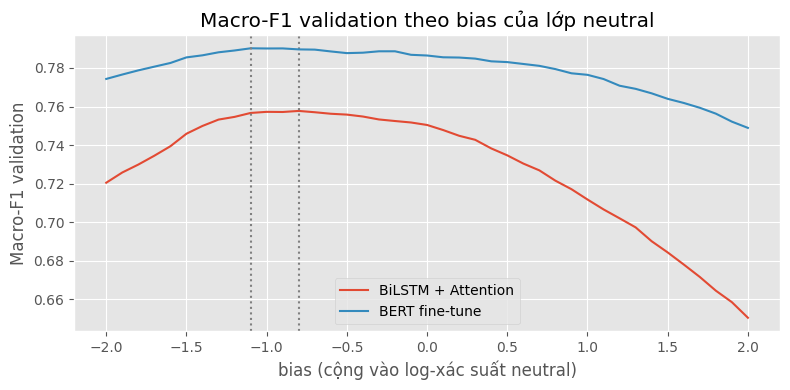

In [58]:
rows, curves = [], {}
for name, vp in val_probs.items():
    best_bias, grid, val_scores = tune_neutral_bias(vp, y_val)
    curves[name] = (grid, val_scores)
    test_probs_m = PRED[name]['probs']
    before = compute_metrics(y_test, test_probs_m.argmax(1))
    after = compute_metrics(y_test, predict_with_neutral_bias(test_probs_m, best_bias))
    rows.append({'Mô hình': name, 'bias chọn trên validation': best_bias,
                 'Macro-F1 validation (bias = 0)': val_scores[np.isclose(grid, 0.0)][0],
                 'Macro-F1 validation (bias đã chọn)': val_scores.max(),
                 'Macro-F1 test (trước)': before['Macro-F1'], 'Macro-F1 test (sau)': after['Macro-F1'],
                 'F1 neutral test (trước)': before['F1 neutral'], 'F1 neutral test (sau)': after['F1 neutral']})
display(pd.DataFrame(rows).set_index('Mô hình').style.format('{:.4f}'))

fig, ax = plt.subplots(figsize=(8, 4))
for name, (grid, sc) in curves.items():
    ax.plot(grid, sc, label=name)
    ax.axvline(grid[sc.argmax()], ls=':', color='gray')
ax.set(title='Macro-F1 validation theo bias của lớp neutral', xlabel='bias (cộng vào log-xác suất neutral)', ylabel='Macro-F1 validation')
ax.legend()
plt.tight_layout()
plt.show()

**Cách đọc:** với BiLSTM, `bias` = −0,8 nâng Macro-F1 test từ 0,7422 lên 0,7551 (+0,013); với BERT-base, `bias` = −1,1 tăng validation 0,7864 → 0,7902 nhưng test giảm nhẹ 0,7877 → 0,7866, tức mức tăng nằm trong nhiễu. Chỉnh ngưỡng giúp mô hình nhỏ bị lệch nhiều nhưng không giúp BERT. Kết quả chính vẫn là bảng mục 6.2 (bias = 0).

## 6.7 Thử nghiệm với câu tự viết
So sánh BiLSTM và BERT-base (đã nạp ở 6.6) trên câu có phủ định, mỉa mai, khen-chê lẫn lộn.

In [59]:
demo_texts = [
    "This coffee is absolutely amazing, I will definitely buy it again!",
    "Not bad at all, actually pretty tasty.",
    "It's okay. Nothing special, but it does the job.",
    "Great, another box arrived completely crushed. Just what I needed.",
    "My dog loves these treats, but they are way too expensive for such a small bag.",
    "I would not recommend this to anyone. Total waste of money.",
]
demo_clean = [clean_text(t) for t in demo_texts]
fmt = lambda p: f'{LABELS[p.argmax()]} ({p.max():.0%})'
pd.DataFrame({'Câu': demo_texts,
              'BiLSTM + Attention': [fmt(p) for p in lstm_predict_texts(bilstm, vocab, demo_texts, CFG['lstm_max_len'])],
              'BERT fine-tune': [fmt(p) for p in predict_transformer(bert, bert_tok, demo_clean, CFG['trf_max_len'], desc='demo')]})

demo:   0%|          | 0/1 [00:00<?, ?it/s]

,Câu,BiLSTM + Attention,BERT fine-tune
0,"This coffee is absolutely amazing, I will definitely buy it again!",positive (100%),positive (100%)
1,"Not bad at all, actually pretty tasty.",neutral (78%),positive (79%)
2,"It's okay. Nothing special, but it does the job.",neutral (100%),neutral (99%)
3,"Great, another box arrived completely crushed. Just what I needed.",positive (87%),positive (99%)
4,"My dog loves these treats, but they are way too expensive for such a small bag.",neutral (84%),neutral (89%)
5,I would not recommend this to anyone. Total waste of money.,negative (100%),negative (100%)


In [60]:
for t in demo_texts[1:5]:
    show_attention(bilstm, vocab, t, CFG['lstm_max_len'])

**Nhận xét (chỉ minh hoạ, 6 câu):**
- **Mỉa mai** (*"Great, another box arrived completely crushed…"*) bị cả hai đoán là positive (BiLSTM 87%, BERT 99%).
- **Neutral:** *"It's okay. Nothing special…"* cả hai đoán đúng (BiLSTM 100%, BERT 99%); câu khen-chê về giá cũng được cả hai đoán neutral (84%, 89%).
- **Phủ định** (*"Not bad at all…"*): BiLSTM neutral (78%), BERT positive (79%); cả hai đều chấp nhận được.
- Các câu rõ ràng khen hoặc chê được đoán đúng.

## 6.8 Kết luận, hạn chế và hướng phát triển

Kết quả trên tập test (80/10/10, seed 42; GPU Tesla T4):

| Mô hình | Accuracy | Macro-F1 | F1 neg | F1 neu | F1 pos | Thời gian train | Suy luận | Số tham số |
|---|---|---|---|---|---|---|---|---|
| **BERT-base** | **0,9074** | **0,7877** | 0,8470 | 0,5540 | 0,9620 | 64,4 phút | 83,7 s | 109,48 triệu |
| BiLSTM + Attention | 0,8788 | 0,7422 | 0,7863 | 0,4916 | 0,9488 | 3,4 phút | 3,7 s | 6,25 triệu |
| Luôn đoán positive | 0,7794 | 0,2920 | 0 | 0 | 0,8760 | – | – | – |

**Kết luận**
1. Cả hai mạng học được tín hiệu thật (Macro-F1 cao hơn mốc 0,292 lần lượt 0,450 và 0,496).
2. BERT-base tốt hơn BiLSTM 0,0455 [+0,0400; +0,0507], ở cả ba lớp: học chuyển giao tốt hơn học từ đầu.
3. Neutral là lớp khó nhất (F1 0,49–0,55); chỉnh ngưỡng chỉ giúp BiLSTM.
4. Chi phí: BERT-base cần ≈19× thời gian huấn luyện và 17,5× số tham số của BiLSTM cho +0,0455 Macro-F1.

**Hạn chế**
- Nhãn yếu: số sao không luôn khớp văn bản (165 review 5 sao bị đoán negative).
- Chia ngẫu nhiên, phân bố nhãn trôi theo thời gian: điểm số không đo hiệu năng trên review tương lai.
- Mỉa mai và ý kiến pha trộn vẫn sai; mỗi mô hình chỉ chạy một seed, BERT mới 2 epoch (chưa bão hoà); chỉ một lĩnh vực (review thực phẩm Amazon 1999–2012).

**Hướng phát triển:** fine-tune BERT nhiều epoch/seed hoặc thử RoBERTa/DeBERTa; chia theo thời gian; GloVe/fastText cho BiLSTM; focal loss hoặc oversampling; cắt đầu + đuôi cho review dài; một tập nhỏ nhãn do người gán.

**Tài liệu tham khảo**
1. McAuley & Leskovec, *From Amateurs to Connoisseurs*, WWW 2013 (bộ dữ liệu).
2. Hochreiter & Schmidhuber, *Long Short-Term Memory*, 1997.
3. Bahdanau et al., *Neural Machine Translation by Jointly Learning to Align and Translate*, ICLR 2015.
4. Vaswani et al., *Attention Is All You Need*, NeurIPS 2017.
5. Devlin et al., *BERT*, NAACL 2019.